# Ca neighboring-ion crosstalk — 729 and 830 nm

Set `WAVELENGTH_NM` in Settings to **729** or **830**, then run the notebook in order. Each run analyzes ion 0 and ion 1 at the selected wavelength using their own focused references and independent alignments. The same HDR, ±5 µm crosstalk, 2×2 matrices, publication maps, and diagnostics apply to either wavelength.

HDR selects the longest valid exposure at each pixel, then reports dark-corrected R+G+B counts per actual exposure second. Subtract the original `dark_20261002_113902_15MHz/dark_calibration.npz` mean interpolated at the actual exposure time. Valid corrected counts must be strictly above `SIGNAL_SIGMA_MULTIPLIER × σ` (default 3σ), where σ is the sample SD of R+G+B across pixels of the matching nominal-exposure BMP in `Dark_Frames/MANUAL` (`ddof=1`, without division by √N). The MANUAL mean is not subtracted. Every raw RGB channel must also be <230. No valid exposure leaves that pixel unavailable, without an unconditional fallback. Exposure exclusions are controlled by `EXCLUDED_EXPOSURES_MS`. The matrix samples +5 µm from ion 0's peak and −5 µm from ion 1's peak.

Alignment and cache names include both ion and wavelength. The existing output directories are unchanged: 729 nm files retain their original names, and 830 nm files use an `_830nm` suffix so results can coexist. Saved notebook outputs may show the previously run wavelength until those cells are rerun. When switching wavelengths, rerun Settings, discovery, alignment, and processing before rerunning the analysis and plots.


## Functions: input and independent alignment

In [23]:
from pathlib import Path
from datetime import datetime
import hashlib
import json
import sys
import re

import numpy as np
import pandas as pd
import tifffile
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from scipy import ndimage
from IPython.display import display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "Analysis/gate_image_profiler.py").is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import importlib
import Analysis.gate_image_profiler as _gate_image_profiler
GateImageProfiler = importlib.reload(_gate_image_profiler).GateImageProfiler


def wavelength_output_path(directory, filename, wavelength_nm=729):
    """Keep 729 nm filenames; suffix other wavelengths in the same directory."""
    path = Path(filename)
    suffix = "" if wavelength_nm == 729 else f"_{int(wavelength_nm)}nm"
    return Path(directory) / f"{path.stem}{suffix}{path.suffix}"


def require_selected_wavelength(items, wavelength_nm):
    """Reject stale datasets/results after changing the wavelength setting."""
    if not items:
        raise RuntimeError("Run Settings and discovery for the selected wavelength first.")
    for entry in items.values():
        dataset = entry.get("dataset") if isinstance(entry.get("dataset"), dict) else entry
        if dataset.get("wavelength_nm") != wavelength_nm:
            raise RuntimeError("Wavelength changed: rerun Settings, discovery, alignment, and processing.")


def require_scan_wavelength(scan, wavelength_nm):
    """Reject matrices and publication maps from a previously selected wavelength."""
    actual = scan.get("wavelength_nm", scan.get("settings", {}).get("wavelength_nm"))
    if actual != wavelength_nm:
        raise RuntimeError("Wavelength changed: rerun the matrix or publication analysis cell first.")


def discover_dataset(folder):
    """Find this dataset's latest complete run and its own preceding reference."""
    folder = Path(folder)
    timestamp = lambda s: datetime.fromisoformat(s.replace("Z", "+00:00"))
    runs = []
    for path in sorted(folder.glob("signal_*/run_metadata.json")):
        metadata = json.loads(path.read_text())
        if metadata.get("status") == "complete" and (path.parent / "exposure_log.csv").is_file():
            runs.append((timestamp(metadata["started_utc"]), path.parent, metadata))
    if not runs:
        raise FileNotFoundError(f"No complete signal run in {folder}")
    started, run_dir, metadata = max(runs, key=lambda item: item[0])
    references = []
    for path in sorted(folder.glob("focused_*.json")):
        ref = json.loads(path.read_text())
        if ref.get("capture_kind") != "focused":
            continue
        image_path = folder / ref["raw_tiff"]
        received = timestamp(ref["frame_received_utc"])
        if image_path.is_file() and received <= started:
            references.append((received, image_path, ref))
    if not references:
        raise FileNotFoundError(f"No focused reference preceding {run_dir.name}")
    _, reference_path, reference_metadata = max(references, key=lambda item: item[0])
    table = pd.read_csv(run_dir / "exposure_log.csv").sort_values(
        ["height_index", "time_index", "exposure_index", "frame_index"]
    ).reset_index(drop=True)
    table.index.name = "image_index"
    table["path"] = table.filename.map(lambda name: run_dir / name)
    if len(table) != metadata["planned_frames"] or not len(table):
        raise ValueError(f"Incomplete exposure log: {run_dir}")
    missing = [str(p) for p in table.path if not p.is_file()]
    if missing:
        raise FileNotFoundError(f"Missing {len(missing)} frames, including {missing[0]}")
    return dict(name=folder.name, folder=folder, run_dir=run_dir, metadata=metadata,
                reference_path=reference_path, reference_metadata=reference_metadata,
                frames=table)


def load_manual_dark_statistics(path):
    """Spatial mean and sample SD of R+G+B in each nominal-exposure dark BMP.

    One image per exposure: SD describes variation across pixels, not the
    uncertainty of the mean or temporal frame-to-frame noise. Ignore alpha.
    """
    path = Path(path)
    files = sorted(p for p in path.iterdir() if p.suffix.lower() == ".bmp")
    if not files:
        raise FileNotFoundError(f"No dark BMP images in {path}")
    records, shape = [], None
    for file in files:
        match = re.fullmatch(r"(\d+(?:[p.]\d+)?)_ms", file.stem)
        if match is None:
            raise ValueError(f"Expected exposure filename such as 0p2_ms.bmp: {file.name}")
        exposure = float(match.group(1).replace("p", "."))
        with Image.open(file) as image:
            rgb = np.asarray(image)
            if image.mode not in ("RGB", "RGBA") or rgb.dtype != np.uint8:
                raise ValueError(f"Expected 8-bit RGB/RGBA dark image: {file}")
            if shape is not None and rgb.shape[:2] != shape:
                raise ValueError("Dark images have inconsistent dimensions")
            shape = rgb.shape[:2]
            counts = rgb[..., :3].sum(axis=-1, dtype=np.float64)
        if counts.size < 2 or exposure <= 0:
            raise ValueError(f"Invalid dark image or exposure: {file}")
        records.append(dict(exposure_ms=exposure, mean_counts=float(counts.mean()),
            std_counts=float(counts.std(ddof=1)), pixels=int(counts.size),
            filename=file.name, sha256=hashlib.sha256(file.read_bytes()).hexdigest()))
    table = pd.DataFrame(records).sort_values("exposure_ms").reset_index(drop=True)
    exposure = table.exposure_ms.to_numpy()
    if np.any(np.diff(exposure) <= 0):
        raise ValueError("Duplicate dark exposure times")
    metadata = dict(width=shape[1], height=shape[0],
        count_definition="R+G+B", std_ddof=1, statistics="spatial across pixels of one image per exposure")
    fingerprint = hashlib.sha256(json.dumps(dict(metadata=metadata,
        records=table.to_dict(orient="records")), sort_keys=True).encode()).hexdigest()
    return dict(path=path, files=files, exposure_ms=exposure,
        counts=table.mean_counts.to_numpy(), sigma_counts=table.std_counts.to_numpy(),
        statistics=table, metadata=metadata, fingerprint=fingerprint)


def dark_statistics_at(dark, exposure_ms):
    """Match nominal exposures in a MANUAL statistics object; never interpolate noise SD."""
    exposure_ms = np.asarray(exposure_ms, dtype=float)
    matches = np.isclose(exposure_ms[..., None], dark["exposure_ms"], rtol=0, atol=1e-6)
    if not np.isfinite(exposure_ms).all() or not np.all(matches.sum(axis=-1) == 1):
        raise ValueError(f"Every signal nominal exposure needs one matching dark BMP: {exposure_ms}")
    indices = matches.argmax(axis=-1)
    return dark["counts"][indices], dark["sigma_counts"][indices]


def load_dark_calibration(path, noise_path):
    """Original NPZ means for subtraction; separate MANUAL BMP spatial SD for noise."""
    path = Path(path)
    with np.load(path, allow_pickle=False) as data:
        if data["exposure_unit"].item() != "ms":
            raise ValueError("Dark calibration exposure unit must be ms")
        if data["dark_count_definition"].item() != "mean over frames and pixels of B+G+R":
            raise ValueError("Dark calibration must be in R+G+B counts")
        exposure = np.asarray(data["actual_exposures_ms"], dtype=float).copy()
        counts = np.asarray(data["dark_counts"], dtype=float).copy()
        metadata = json.loads(data["metadata_json"].item())
    if (exposure.ndim != 1 or counts.shape != exposure.shape or len(exposure) < 2
            or not np.isfinite(exposure).all() or not np.isfinite(counts).all()
            or np.any(exposure <= 0) or np.any(counts < 0)):
        raise ValueError("Invalid original dark calibration")
    order = np.argsort(exposure)
    exposure, counts = exposure[order], counts[order]
    if np.any(np.diff(exposure) <= 0):
        raise ValueError("Original dark exposure grid must be unique")
    noise = load_manual_dark_statistics(noise_path)
    for key in ("width", "height"):
        if metadata[key] != noise["metadata"][key]:
            raise ValueError(f"Original calibration / MANUAL dark mismatch: {key}")
    fingerprint = hashlib.sha256(json.dumps(dict(
        subtraction_npz_sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
        noise_fingerprint=noise["fingerprint"],
        method="original interpolated R+G+B mean; MANUAL spatial R+G+B sample SD"
    ), sort_keys=True).encode()).hexdigest()
    dark = dict(path=path, exposure_ms=exposure, counts=counts, metadata=metadata,
        noise=noise, noise_path=Path(noise_path), fingerprint=fingerprint)
    statistics = noise["statistics"].rename(columns={"mean_counts": "manual_mean_counts_diagnostic"}).copy()
    statistics["original_mean_at_nominal_exposure_counts"] = dark_at(dark, statistics.exposure_ms)
    dark["statistics"] = statistics
    return dark


def dark_at(dark, exposure_ms):
    """Linearly interpolate the original calibration mean at actual exposure time."""
    exposure_ms = np.asarray(exposure_ms, dtype=float)
    grid = dark["exposure_ms"]
    if (not np.isfinite(exposure_ms).all() or np.any(exposure_ms < grid[0])
            or np.any(exposure_ms > grid[-1])):
        raise ValueError(f"Exposure outside dark calibration range [{grid[0]}, {grid[-1]}] ms")
    return np.interp(exposure_ms, grid, dark["counts"])


def rotate_pixels(image, angle_deg):
    """Rotate intensity values on the fixed full-size pixel grid, filling corners with zero.

    Selection zoom windows never slice the image. Coordinates are not rotated,
    rescaled, or expanded; only the intensity array receives this transform.
    """
    return ndimage.rotate(image, float(angle_deg), axes=(1, 0), reshape=False,
                          order=0, mode="constant", cval=0, prefilter=False)


def reference_signature(dataset):
    path = dataset["reference_path"]
    return dict(reference_name=path.name, reference_size=path.stat().st_size,
                reference_mtime_ns=path.stat().st_mtime_ns)


def save_alignment(dataset, record, directory):
    """Save only this dataset's alignment; no cross-dataset registration is used."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    record = dict(record, **reference_signature(dataset))
    (directory / f"{dataset['name']}.json").write_text(json.dumps(record, indent=2) + "\n")
    return record


def load_alignment(dataset, directory):
    path = Path(directory) / f"{dataset['name']}.json"
    if not path.is_file():
        return None
    record = json.loads(path.read_text())
    if any(record.get(key) != value for key, value in reference_signature(dataset).items()):
        return None
    return record


def select_alignment(dataset, directory, *, pixel_pitch_um=(5.3, 5.3), magnification=50.0,
                     zoom_brightness_gain=4.0):
    """Zoom box → angle pair → second zoom box → origin midpoint pair.

    The boxes set view limits only. All points keep full-image pixel coordinates.
    Rotate only the intensity on the original pixel grid; the second point pair
    sets its coordinate origin after rotation, without rotating the axes.
    """
    print(f"Aligning {dataset['name']}: {dataset['reference_path'].name}", flush=True)
    profiler = GateImageProfiler(pixel_pitch_um=pixel_pitch_um, magnification=magnification,
        ion_relative_to_wg_lens_um=0, wg_lens_relative_to_trench_um=0, interpolation_order=0)
    alignment = profiler.align_white_light(dataset["reference_path"], brightness_offset=0,
                                          select_rois=True, zoom_brightness_gain=zoom_brightness_gain)
    return save_alignment(dataset, dict(angle_deg=alignment.angle_deg,
        origin_px=list(alignment.trench_center_px), pixel_pitch_um=list(pixel_pitch_um),
        magnification=float(magnification),
        method="independent manual selection with two view-only zoom boxes",
        zoom_display_brightness_gain=float(zoom_brightness_gain),
        rotation_roi_px=alignment.rotation_roi_px.tolist(),
        rotation_points_px=alignment.rotation_points_px.tolist(),
        origin_roi_px=alignment.center_roi_px.tolist(),
        origin_points_px=alignment.trench_edges_px.tolist()), directory)


def image_axes(shape, alignment):
    ny, nx = shape[:2]
    dx, dy = np.asarray(alignment["pixel_pitch_um"], dtype=float) / alignment["magnification"]
    cx, cy = alignment["origin_px"]
    if not (0 <= cx < nx and 0 <= cy < ny and dx > 0 and dy > 0):
        raise ValueError("Invalid alignment origin or sample spacing")
    x, y = (np.arange(nx) - cx) * dx, (np.arange(ny) - cy) * dy
    extent = (x[0]-dx/2, x[-1]+dx/2, y[-1]+dy/2, y[0]-dy/2)
    return x, y, extent


def preview_references(datasets, alignments):
    fig, axes = plt.subplots(1, len(datasets), figsize=(5*len(datasets), 4), constrained_layout=True)
    for ax, (ion, dataset) in zip(np.atleast_1d(axes), datasets.items()):
        if ion not in alignments:
            ax.text(.5, .5, f"{dataset['name']}\nAlignment still needed", ha="center", transform=ax.transAxes)
            continue
        a = alignments[ion]
        image = rotate_pixels(tifffile.imread(dataset["reference_path"]), a["angle_deg"])
        _, _, extent = image_axes(image.shape, a)
        ax.imshow(image, origin="upper", extent=extent)
        ax.axhline(0, color="cyan", lw=.7)
        ax.axvline(0, color="cyan", lw=.7)
        ax.set(title=f"{dataset['name']}\nrotation = {a['angle_deg']:.4f} deg",
               xlabel="Axial x (um)", ylabel="Radial y (um)")
    plt.show()
    plt.close(fig)


## Functions: HDR, axial sampling, and neighboring matrices

In [24]:
def _fingerprint(dataset, alignment, dark, signal_sigma_multiplier, max_rgb, excluded_exposures_ms=()):
    files = [dataset["run_dir"] / "exposure_log.csv", *dataset["frames"].path]
    payload = dict(version=6, signal_sigma_multiplier=float(signal_sigma_multiplier), fallback_method="none", dark_fingerprint=dark["fingerprint"], hdr_selection="longest_valid_exposure", alignment=alignment, max_rgb=float(max_rgb),
                   files=[(str(p), p.stat().st_size, p.stat().st_mtime_ns) for p in files])
    excluded = sorted(set(map(float, excluded_exposures_ms)))
    if excluded:
        payload["excluded_requested_exposure_ms"] = excluded
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()


def process_dataset(dataset, alignment, dark, *, signal_sigma_multiplier=3.0, max_rgb=255*0.9, cache_dir=None,
                    excluded_exposures_ms=()):
    """Use the longest exposure passing both RGB and corrected-count noise checks.

    Subtract the original NPZ mean interpolated at the frame's actual exposure.
    Require corrected R+G+B > multiplier * MANUAL spatial sample SD for its
    nominal exposure, and every raw RGB channel < max_rgb. Then divide by seconds.
    No valid exposure leaves that pixel unavailable; no saturated/noise fallback.
    """
    if (not np.isfinite(signal_sigma_multiplier) or signal_sigma_multiplier < 0
            or not np.isfinite(max_rgb) or not 0 < max_rgb <= 255):
        raise ValueError("Require sigma multiplier >= 0 and 0 < max_rgb <= 255")
    for key in ("camera_id", "pixel_clock_mhz", "width", "height", "pixel_format"):
        if key in dark["metadata"] and dark["metadata"][key] != dataset["metadata"][key]:
            raise ValueError(f"Dark calibration mismatch for {dataset['name']}: {key}")
    frames = dataset["frames"]
    excluded = np.asarray(excluded_exposures_ms, dtype=float)
    if excluded.ndim != 1 or not np.isfinite(excluded).all() or np.any(excluded <= 0):
        raise ValueError("Excluded nominal exposure times must be a finite positive list")
    excluded = sorted(set(excluded.tolist()))
    include_frame = np.ones(len(frames), dtype=bool)
    for exposure in excluded:
        include_frame &= ~np.isclose(frames.requested_exposure_ms, exposure, rtol=0, atol=1e-6)
    seconds = frames.actual_exposure_ms.to_numpy(dtype=float) / 1000
    if not np.isfinite(seconds).all() or np.any(seconds <= 0):
        raise ValueError("Actual exposure times must be positive and finite")
    dark_levels = dark_at(dark, frames.actual_exposure_ms)
    _, dark_sigmas = dark_statistics_at(dark["noise"], frames.requested_exposure_ms)
    thresholds = float(signal_sigma_multiplier) * dark_sigmas
    reference = rotate_pixels(tifffile.imread(dataset["reference_path"]), alignment["angle_deg"])
    x, y, extent = image_axes(reference.shape, alignment)
    reference_corrected = reference.sum(axis=-1, dtype=np.uint16).astype(np.float32)
    reference_corrected -= float(dark_at(dark, dataset["reference_metadata"]["exposure_ms"]))
    np.maximum(reference_corrected, 0, out=reference_corrected)
    fingerprint = _fingerprint(dataset, alignment, dark, signal_sigma_multiplier, max_rgb, excluded)
    base = dict(dataset=dataset, alignment=alignment, x_um=x, y_um=y, extent=extent,
                reference_corrected=reference_corrected, signal_sigma_multiplier=float(signal_sigma_multiplier),
                signal_threshold="corrected R+G+B > multiplier * MANUAL spatial sample SD",
                dark_fingerprint=dark["fingerprint"], dark_statistics=dark["statistics"].copy(),
                max_rgb=max_rgb, fallback_method="none",
                excluded_exposures_ms=excluded, hdr_selection="longest_valid_exposure")
    cache_path = None if cache_dir is None else Path(cache_dir) / f"{dataset['name']}.npz"
    if cache_path is not None and cache_path.is_file():
        with np.load(cache_path, allow_pickle=False) as cached:
            if cached["fingerprint"].item() == fingerprint:
                info = json.loads(cached["tables_json"].item())
                base.update(rate=cached["rate"].copy(), source=cached["source"].copy(),
                            fallback=cached["fallback"].copy(),
                            heights_um=cached["heights_um"].copy())
                for key, records in info.items():
                    base[key] = pd.DataFrame(records)
                print(f"{dataset['name']}: reused processed cache", flush=True)
                return base
    groups = list(frames.groupby("height_index", sort=True).indices.items())
    shape = (len(groups), *reference.shape[:2])
    rate = np.zeros(shape, dtype=np.float32)
    source_dtype = np.int16 if len(frames) < 32767 else np.int32
    source = np.full(shape, -1, dtype=source_dtype)
    fallback = np.zeros(shape, dtype=bool)
    heights, summary, saturation, comparisons = [], [], [], []
    for slot, (height_id, indices) in enumerate(groups):
        indices = np.asarray(indices)
        physical_heights = frames.iloc[indices].target_height_um.to_numpy()
        if not np.allclose(physical_heights, physical_heights[0], rtol=0, atol=1e-5):
            raise ValueError("Inconsistent heights within an exposure group")
        height = float(physical_heights[0])
        heights.append(height)
        indices = indices[include_frame[indices]]
        if not len(indices):
            raise ValueError(f"All exposures excluded at height {height:g} um")
        candidates = []
        for index in indices[np.argsort(seconds[indices], kind="stable")]:
            raw = tifffile.imread(frames.iloc[index].path)
            if raw.shape != reference.shape or raw.dtype != np.uint8:
                raise ValueError(f"Unexpected RGB shape/dtype in {frames.iloc[index].path}")
            if np.isclose(frames.iloc[index].requested_exposure_ms, .2, rtol=0, atol=1e-6):
                maxima = raw.max(axis=(0, 1))
                saturation.append(dict(height_index=int(height_id), height_um=height,
                    max_R=int(maxima[0]), max_G=int(maxima[1]), max_B=int(maxima[2]),
                    saturated_pixels=int(np.count_nonzero(np.any(raw >= 255, axis=-1))),
                    all_channels_below_sat=bool((maxima < 255).all())))
            rgb = rotate_pixels(raw, alignment["angle_deg"])
            corrected = rgb.sum(axis=-1, dtype=np.uint16).astype(np.float32)
            corrected -= np.float32(dark_levels[index])
            np.maximum(corrected, 0, out=corrected)
            channel_peak = rgb.max(axis=-1)
            candidate_rate = corrected / seconds[index]
            valid = (corrected > thresholds[index]) & (channel_peak < max_rgb) & np.isfinite(candidate_rate)
            # Ascending exposure order: each valid longer exposure overwrites the prior one.
            # Counts must pass the exposure-specific MANUAL noise threshold before selection.
            take = valid
            rate[slot, take] = candidate_rate[take]
            source[slot, take] = index
            candidates.append((int(index), corrected, channel_peak))
        threshold_valid = source[slot] >= 0
        available = (source[slot] >= 0) & np.isfinite(rate[slot]) & (rate[slot] > 0)
        record = dict(height_index=int(height_id), height_um=height,
            valid_pixels_pct=float(100*threshold_valid.mean()),
            fallback_pixels=int(fallback[slot].sum()), fallback_pixels_pct=float(100*fallback[slot].mean()),
            positive_pixels_pct=float(100*available.mean()), peak_uses_fallback=False,
            peak_x_um=np.nan, peak_y_um=np.nan,
            peak_rate_counts_s=np.nan, peak_exposure_ms=np.nan,
            peak_requested_exposure_ms=np.nan, peak_uses_0p2_ms=False)
        if available.any():
            row, col = np.unravel_index(np.argmax(np.where(available, rate[slot], -np.inf)), rate[slot].shape)
            chosen = int(source[slot, row, col])
            nominal = float(frames.iloc[chosen].requested_exposure_ms)
            record.update(peak_uses_fallback=bool(fallback[slot, row, col]),
                peak_x_um=float(x[col]), peak_y_um=float(y[row]),
                peak_rate_counts_s=float(rate[slot, row, col]),
                peak_exposure_ms=float(seconds[chosen]*1000), peak_requested_exposure_ms=nominal,
                peak_uses_0p2_ms=bool(np.isclose(nominal, .2, rtol=0, atol=1e-6)))
            for index, counts_image, channel_image in candidates:
                counts, channel = float(counts_image[row, col]), int(channel_image[row, col])
                comparisons.append(dict(height_index=int(height_id), height_um=height,
                    requested_exposure_ms=float(frames.iloc[index].requested_exposure_ms),
                    actual_exposure_ms=float(seconds[index]*1000), corrected_counts=counts,
                    max_rgb_channel=channel, rate_counts_s=counts/seconds[index],
                    dark_mean_counts=float(dark_levels[index]), dark_std_counts=float(dark_sigmas[index]),
                    minimum_corrected_counts=float(thresholds[index]), signal_threshold_applied=True,
                    passes_thresholds=bool(counts > thresholds[index] and channel < max_rgb),
                    selected_at_peak=bool(index == chosen), selected_as_fallback=bool(index == chosen and fallback[slot, row, col])))
        summary.append(record)
        del candidates
        if slot == 0 or (slot+1) % 5 == 0 or slot+1 == len(groups):
            print(f"{dataset['name']}: {slot+1}/{len(groups)} heights", flush=True)
    base.update(rate=rate, source=source, fallback=fallback, heights_um=np.asarray(heights),
                summary=pd.DataFrame(summary), saturation=pd.DataFrame(saturation),
                comparisons=pd.DataFrame(comparisons))
    if cache_path is not None:
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        info = {key: json.loads(base[key].to_json(orient="records"))
                for key in ("summary", "saturation", "comparisons")}
        np.savez_compressed(cache_path, fingerprint=fingerprint, rate=rate, source=source, fallback=fallback,
                           heights_um=base["heights_um"], tables_json=json.dumps(info))
    return base


def height_slot(result, height_um, tolerance=1e-4):
    matches = np.flatnonzero(np.isclose(result["heights_um"], height_um, rtol=0, atol=tolerance))
    if len(matches) != 1:
        raise ValueError(f"Height {height_um:g} um not uniquely available in {result['dataset']['name']}")
    return int(matches[0])


def axial_profile(result, slot, y_um=None):
    """Use the brightest-pixel row or the nearest measured row to a requested y."""
    image = result["rate"][slot]
    valid = (result["source"][slot] >= 0) & np.isfinite(image) & (image > 0)
    x, y = result["x_um"], result["y_um"]
    if y_um is None:
        if not valid.any():
            return np.full(len(x), np.nan), np.nan, np.nan, np.nan
        row, _ = np.unravel_index(np.argmax(np.where(valid, image, -np.inf)), image.shape)
        profile = np.where(valid[row], image[row], np.nan)
        selected_y = float(y[row])
    else:
        if not np.isfinite(y_um) or not y[0] <= y_um <= y[-1]:
            raise ValueError(f"Requested y={y_um} outside {result['dataset']['name']} image")
        row = int(np.argmin(np.abs(y-y_um)))
        profile = np.where(valid[row], image[row], np.nan)
        selected_y = float(y[row])
    if not np.isfinite(profile).any():
        return profile, np.nan, selected_y, np.nan
    col = int(np.nanargmax(profile))
    return profile, float(x[col]), selected_y, float(profile[col])


def sample_linear(x, values, target):
    """Interpolate linear rate between adjacent valid pixels, without gap bridging."""
    x, values = np.asarray(x), np.asarray(values)
    if not np.isfinite(target) or not x[0] <= target <= x[-1]:
        return np.nan
    right = int(np.searchsorted(x, target))
    if right < len(x) and np.isclose(x[right], target, rtol=0, atol=1e-12):
        value = values[right]
    elif right == 0 or right == len(x) or not np.isfinite(values[[right-1, right]]).all():
        return np.nan
    else:
        fraction = (target-x[right-1])/(x[right]-x[right-1])
        value = (1-fraction)*values[right-1]+fraction*values[right]
    return float(value) if np.isfinite(value) and value > 0 else np.nan


def ratio_db(value, reference):
    return float(10*np.log10(value/reference)) if (np.isfinite(value) and value > 0
        and np.isfinite(reference) and reference > 0) else np.nan


def crosstalk_by_height(result, offset_um=5, y_um=None):
    if not np.isfinite(offset_um) or offset_um <= 0:
        raise ValueError("Offset must be positive")
    records = []
    for slot, height in enumerate(result["heights_um"]):
        profile, peak_x, peak_y, peak = axial_profile(result, slot, y_um)
        record = dict(height_um=float(height), peak_x_um=peak_x, sample_y_um=peak_y,
                      peak_rate_counts_s=peak)
        for name, sign in (("minus", -1), ("plus", 1)):
            target = peak_x+sign*offset_um
            rate = sample_linear(result["x_um"], profile, target)
            record[f"sample_x_{name}_um"] = target
            record[f"crosstalk_{name}_db"] = ratio_db(rate, peak)
        records.append(record)
    return pd.DataFrame(records)


def neighboring_matrices(results, y_um=None, pitch_um=5, index_x_direction=1):
    """Use only each driven image's own peak, row, and nearest measured pixels.

    Rows are measured-ion locations; columns are driven ions. For drive i and
    measured location j, sample x_peak_i + direction*(j-i)*pitch_um in dataset i only.
    For these Ca images, direction=+1: drive 0 samples +5 um, drive 1 samples -5 um.
    Normalize to that same dataset's peak on the same row and at the same height.
    y_um accepts None, a shared numeric coordinate, or {ion: coordinate_or_None}.
    Missing dictionary entries use that ion's brightest-pixel row.
    """
    if not np.isfinite(pitch_um) or pitch_um <= 0:
        raise ValueError("Ion pitch must be positive and finite")
    if index_x_direction not in (-1, 1):
        raise ValueError("Ion-index axial direction must be -1 or +1")
    ions = sorted(results)
    if isinstance(y_um, dict) and set(y_um)-set(ions):
        raise ValueError("Radial-cut dictionary contains unknown ion indices")
    common = sorted(set.intersection(*(set(np.round(results[i]["heights_um"], 6)) for i in ions)))
    if not common:
        raise ValueError("The datasets have no common physical heights")
    matrices = np.full((len(common), len(ions), len(ions)), np.nan)
    records, positions = [], []
    for hslot, height in enumerate(common):
        for column, driven in enumerate(ions):
            result = results[driven]
            selected_y_um = y_um.get(driven) if isinstance(y_um, dict) else y_um
            profile, own_x, own_y, own_peak = axial_profile(
                result, height_slot(result, height), selected_y_um)
            positions.append(dict(height_um=height, ion=driven, peak_x_um=own_x,
                                  peak_y_um=own_y, peak_rate_counts_s=own_peak))
            x = result["x_um"]
            for row, measured in enumerate(ions):
                offset = index_x_direction*(measured-driven)*pitch_um
                target_x = own_x+offset
                actual_x, rate = np.nan, np.nan
                if np.isfinite(target_x) and x[0] <= target_x <= x[-1]:
                    index = int(np.argmin(np.abs(x-target_x)))
                    actual_x = float(x[index])
                    if np.isfinite(profile[index]) and profile[index] > 0:
                        rate = float(profile[index])
                value = ratio_db(rate, own_peak)
                matrices[hslot, row, column] = value
                records.append(dict(height_um=height, measured_ion=measured, driven_ion=driven,
                    driven_peak_x_um=own_x, requested_offset_um=offset,
                    requested_x_um=target_x, sample_x_um=actual_x,
                    actual_offset_um=actual_x-own_x, requested_y_um=selected_y_um, sample_y_um=own_y,
                    rate_counts_s=rate, reference_rate_counts_s=own_peak,
                    crosstalk_db=value, sampling_mode="driven_peak_nearest_pixel"))
    return dict(ions=ions, heights_um=np.asarray(common), db=matrices,
                table=pd.DataFrame(records), peak_positions=pd.DataFrame(positions),
                mode="driven_peak_nearest_pixel")


## Functions: plots

In [25]:
def plot_hdr(result, heights_um, db_floor=-40, y_um=None):
    """Display an axial cut at the nearest measured y; None follows the brightest row."""
    frames = result["dataset"]["frames"]
    nominal = frames.requested_exposure_ms.to_numpy()
    from matplotlib.colors import ListedColormap
    all_levels = np.sort(np.unique(nominal))
    excluded = result.get("excluded_exposures_ms", [])
    eligible = np.ones(len(all_levels), dtype=bool)
    for exposure in excluded:
        eligible &= ~np.isclose(all_levels, exposure, rtol=0, atol=1e-6)
    levels = all_levels[eligible]
    if not len(levels):
        raise ValueError("No eligible exposure levels to plot")
    # Preserve the original exposure colors across ions, while hiding excluded levels.
    base_colors = plt.get_cmap("viridis", len(all_levels))(np.arange(len(all_levels)))
    exposure_cmap = ListedColormap(base_colors[eligible])
    exposure_cmap.set_bad("lightgray")
    norm = BoundaryNorm(np.arange(len(levels)+1)-.5, len(levels))
    cmap = plt.get_cmap("inferno").copy()
    cmap.set_bad("lightgray")
    heights_um = result["heights_um"] if heights_um is None else heights_um
    for height in heights_um:
        slot = height_slot(result, height)
        profile, px, py, peak = axial_profile(result, slot, y_um=y_um)
        if not np.isfinite(peak):
            continue
        valid = result["source"][slot] >= 0
        image = np.full(valid.shape, np.nan, dtype=np.float32)
        # Keep the full image normalized to its global peak when selecting a weaker row.
        image_peak = float(np.max(result["rate"][slot, valid]))
        image[valid] = 10*np.log10(result["rate"][slot, valid]/image_peak)
        category = np.zeros(valid.shape, dtype=np.int16)
        category[valid] = np.searchsorted(levels, nominal[result["source"][slot, valid]])
        fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
        fig.suptitle(f"{result['dataset']['name']} | height = {height:g} um")
        im = axes[0].imshow(image, origin="upper", extent=result["extent"], cmap=cmap,
                            vmin=db_floor, vmax=0, interpolation="nearest")
        axes[0].plot(px, py, "+", color="cyan")
        axes[0].axhline(py, color="cyan", ls="--", lw=.7)
        axes[0].set(title="HDR rate", xlabel="Axial x (um)", ylabel="Radial y (um)")
        fig.colorbar(im, ax=axes[0], label="Intensity / image peak (dB)")
        axes[1].plot(result["x_um"], 10*np.log10(profile/peak), lw=1)
        axes[1].plot(px, 0, "ro", ms=4)
        row_title = f"Axial row at y={py:.3f} um"
        if y_um is not None:
            row_title += f" (requested {float(y_um):g})"
        axes[1].set(title=row_title, xlabel="Axial x (um)",
                    ylabel="Intensity / selected-row peak (dB)", ylim=(db_floor, 1))
        axes[1].grid(alpha=.3)
        im = axes[2].imshow(np.ma.array(category, mask=~valid), origin="upper",
            extent=result["extent"], cmap=exposure_cmap, norm=norm, interpolation="nearest")
        cb = fig.colorbar(im, ax=axes[2], ticks=np.arange(len(levels)))
        cb.set_ticklabels([f"{t:g}" for t in levels])
        cb.set_label("Selected exposure (ms; nominal)")
        axes[2].axhline(py, color="cyan", ls="--", lw=.7)
        axes[2].set(title="Exposure selection", xlabel="Axial x (um)", ylabel="Radial y (um)")
        plt.show()
        plt.close(fig)


def plot_crosstalk_scan(tables, offset_um=5, wavelength_nm=None):
    fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
    for color, (ion, table) in zip(plt.get_cmap("tab10").colors, sorted(tables.items())):
        for side, sign, style in (("minus", "-", "-"), ("plus", "+", "--")):
            ax.plot(table.height_um, table[f"crosstalk_{side}_db"], style, color=color,
                    marker="o", ms=3, label=f"Ion {ion:+d}: x_peak {sign} {offset_um:g} um")
    ax.set(xlabel="Height above chip (um)", ylabel="Crosstalk / row peak (dB)",
           title="Axial crosstalk versus height" + (f" · {wavelength_nm} nm" if wavelength_nm is not None else ""))
    ax.grid(alpha=.3)
    ax.legend(fontsize=9, ncol=2)
    plt.show()
    plt.close(fig)


def plot_neighbor_matrix(scan, height_um, db_floor=-40, font_family="Arial", font_size=16, show=True):
    indices = np.flatnonzero(np.isclose(scan["heights_um"], height_um, rtol=0, atol=1e-4))
    if len(indices) != 1:
        raise ValueError("Select a height common to all datasets")
    values = scan["db"][int(indices[0])]
    labels = [rf"Ion$_{{{int(i)}}}$" for i in scan["ions"]]
    with plt.rc_context(_publication_style(font_family, font_size)):
        cmap = plt.get_cmap("inferno").copy()
        cmap.set_bad("lightgray")
        fig, ax = plt.subplots(figsize=(7.2, 6), constrained_layout=True)
        im = ax.imshow(values, vmin=db_floor, vmax=0, cmap=cmap, interpolation="nearest")
        ax.set(xticks=np.arange(len(labels)), xticklabels=labels,
               yticks=np.arange(len(labels)), yticklabels=labels,
               xlabel="Driven ion location index", ylabel="Measured ion location index",
               title="Crosstalk matrix at focus" + (f" · {scan['wavelength_nm']} nm" if "wavelength_nm" in scan else ""))
        for row, col in np.ndindex(values.shape):
            value = values[row, col]
            text = f"{value:.1f}" if np.isfinite(value) else "N/A"
            ax.text(col, row, text, ha="center", va="center", fontsize=font_size,
                    color="black" if np.isfinite(value) and value > -8 else "white")
        fig.colorbar(im, ax=ax, label="Crosstalk (dB)")
        if show:
            plt.show()
            plt.close(fig)
            return None
        return fig


def plot_neighbor_scan(scan):
    fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
    for driven in scan["ions"]:
        for measured in scan["ions"]:
            if abs(driven-measured) != 1:
                continue
            table = scan["table"]
            subset = table[(table.driven_ion == driven) & (table.measured_ion == measured)]
            ax.plot(subset.height_um, subset.crosstalk_db, marker="o", ms=3,
                    label=f"Drive {driven:+d} -> measure {measured:+d}")
    ax.set(xlabel="Height above chip (um)", ylabel="Neighbor crosstalk (dB)",
           title="Nearest-neighbor crosstalk versus height")
    ax.grid(alpha=.3)
    ax.legend(fontsize=9, ncol=2)
    plt.show()
    plt.close(fig)


def plot_matrix_grid(scan, db_floor=-40, columns=4):
    rows = int(np.ceil(len(scan["heights_um"])/columns))
    fig, axes = plt.subplots(rows, columns, figsize=(3.1*columns, 2.8*rows),
                             constrained_layout=True, squeeze=False)
    cmap = plt.get_cmap("inferno").copy()
    cmap.set_bad("lightgray")
    labels = [f"{i:+d}" for i in scan["ions"]]
    for slot, ax in enumerate(axes.flat):
        if slot >= len(scan["heights_um"]):
            ax.set_visible(False)
            continue
        values = scan["db"][slot]
        im = ax.imshow(values, vmin=db_floor, vmax=0, cmap=cmap, interpolation="nearest")
        ax.set(title=f"{scan['heights_um'][slot]:g} um", xticks=np.arange(len(labels)),
               xticklabels=labels, yticks=np.arange(len(labels)), yticklabels=labels,
               xlabel="Driven ion", ylabel="Measured ion")
        for row, col in np.ndindex(values.shape):
            value = values[row, col]
            ax.text(col, row, f"{value:.1f}" if np.isfinite(value) else "N/A",
                ha="center", va="center", fontsize=8,
                color="black" if np.isfinite(value) and value > -8 else "white")
    fig.colorbar(im, ax=[a for a in axes.flat if a.get_visible()], shrink=.7,
                 label="Intensity / driven-ion peak (dB)")
    plt.show()
    plt.close(fig)


def audit_hdr_exposure_selection(result, dark, height_um=75.0, y_um=14.0):
    """Verify current longest-valid HDR and compare with the former maximum-rate rule.

    Both strategies use the same dark subtraction, thresholds, rotation, and
    included frames. The far-field ROI is >20 um from the 2-D peak in BOTH
    coordinates, excluding rotated image corners and a 20-pixel border.
    """
    slot = height_slot(result, height_um)
    frames = result["dataset"]["frames"]
    x, y = result["x_um"], result["y_um"]
    current = result["rate"][slot]
    peak_row, peak_col = np.unravel_index(np.argmax(current), current.shape)
    row = peak_row if y_um is None else int(np.argmin(abs(y-float(y_um))))
    col = int(np.argmax(current[row]))
    points = {"2D peak": (peak_row, peak_col), "selected-row peak": (row, col)}
    for offset in (5.0, 25.0):
        target = x[col] + offset
        if x[0] <= target <= x[-1]:
            points[f"selected row, peak + {offset:g} um"] = (row, int(np.argmin(abs(x-target))))
    footprint = rotate_pixels(np.ones(current.shape, dtype=np.uint8), result["alignment"]["angle_deg"]) > 0
    roi = (abs(y[:, None]-y[peak_row]) > 20) & (abs(x[None, :]-x[peak_col]) > 20) & footprint
    roi[:20] = False; roi[-20:] = False; roi[:, :20] = False; roi[:, -20:] = False
    if not roi.any():
        raise ValueError("No pixels in the far-field diagnostic ROI")
    longest_source = np.full(current.shape, -1, dtype=result["source"].dtype)
    longest_rate = np.zeros(current.shape, dtype=np.float32)
    rebuilt_source = np.full_like(longest_source, -1)
    rebuilt_rate = np.zeros_like(longest_rate)
    candidates = frames.index[np.isclose(frames.target_height_um, height_um, rtol=0, atol=1e-4)]
    candidates = sorted(candidates, key=lambda i: frames.loc[i, "actual_exposure_ms"])
    pixel_rows, background = [], []
    for index in candidates:
        frame = frames.loc[index]
        nominal = float(frame.requested_exposure_ms)
        if any(np.isclose(nominal, value, rtol=0, atol=1e-6)
               for value in result["excluded_exposures_ms"]):
            continue
        actual = float(frame.actual_exposure_ms)
        rgb = rotate_pixels(tifffile.imread(frame.path), result["alignment"]["angle_deg"])
        raw = rgb.sum(axis=-1, dtype=np.uint16).astype(np.float32)
        dark_level = float(dark_at(dark, actual))
        corrected = np.maximum(raw-np.float32(dark_level), 0)
        rate = corrected/(actual/1000)
        channel = rgb.max(axis=-1)
        _, dark_sigma = dark_statistics_at(dark["noise"], nominal)
        minimum_counts = result["signal_sigma_multiplier"] * float(dark_sigma)
        valid = (corrected > minimum_counts) & (channel < result["max_rgb"]) & np.isfinite(rate)
        take = valid & (rate > rebuilt_rate)
        rebuilt_rate[take], rebuilt_source[take] = rate[take], index
        # Ascending exposure order: overwrite every valid pixel with the longer exposure.
        longest_rate[valid], longest_source[valid] = rate[valid], index
        for point, (r, c) in points.items():
            pixel_rows.append(dict(point=point, x_um=x[c], y_um=y[r], exposure_ms=nominal,
                actual_exposure_ms=actual, raw_counts=float(raw[r, c]), dark_counts=dark_level, dark_std_counts=float(dark_sigma), minimum_corrected_counts=minimum_counts,
                corrected_counts=float(corrected[r, c]), rate_counts_s=float(rate[r, c]),
                max_channel=int(channel[r, c]), valid=bool(valid[r, c]),
                selected_current=bool(result["source"][slot, r, c] == index)))
        background.append(dict(exposure_ms=nominal, actual_exposure_ms=actual,
            dark_counts=dark_level, dark_std_counts=float(dark_sigma), minimum_corrected_counts=minimum_counts, raw_mean_counts=float(raw[roi].mean()),
            raw_mean_rate_counts_s=float(raw[roi].mean()/(actual/1000)),
            corrected_mean_rate_counts_s=float(rate[roi].mean()),
            valid_roi_percent=float(100*valid[roi].mean())))
    if not np.array_equal(longest_source, result["source"][slot]):
        raise RuntimeError("Rebuilt source map differs from cached HDR; rerun processing")
    np.testing.assert_allclose(longest_rate, current, rtol=1e-6, atol=1e-5)
    usage = []
    for label, source in (("Current: longest valid", longest_source),
                          ("Comparison: maximum rate", rebuilt_source)):
        for nominal in sorted(frames.loc[candidates, "requested_exposure_ms"].unique()):
            ids = frames.index[np.isclose(frames.requested_exposure_ms, nominal, rtol=0, atol=1e-6)]
            usage.append(dict(strategy=label, exposure_ms=nominal,
                              far_field_percent=float(100*np.isin(source[roi], ids).mean())))
    return dict(height_um=float(result["heights_um"][slot]), result=result, roi=roi,
                current_source=longest_source, longest_source=longest_source,
                maximum_rate_source=rebuilt_source, maximum_rate_rate=rebuilt_rate,
                longest_rate=longest_rate, pixels=pd.DataFrame(pixel_rows),
                background=pd.DataFrame(background), usage=pd.DataFrame(usage))


def plot_hdr_exposure_audit(audit):
    """Display diagnostics inline only; no figures are exported."""
    from matplotlib.colors import ListedColormap
    result = audit["result"]
    frames = result["dataset"]["frames"]
    levels = np.sort(audit["background"].exposure_ms.unique())
    cmap = ListedColormap(plt.get_cmap("tab10")(np.linspace(0, 1, len(levels))))
    cmap.set_bad("#cccccc")
    norm = BoundaryNorm(np.arange(len(levels)+1)-0.5, len(levels))
    with plt.rc_context({"font.family": "Arial", "font.size": 12}):
        fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)
        for ax, key, title in zip(axes[:2], ("current_source", "maximum_rate_source"),
                ("Current: longest valid exposure", "Comparison: maximum counts/s")):
            source = audit[key]
            image = np.full(source.shape, np.nan)
            for category, exposure in enumerate(levels):
                ids = frames.index[np.isclose(frames.requested_exposure_ms, exposure, rtol=0, atol=1e-6)]
                image[np.isin(source, ids)] = category
            im = ax.imshow(np.ma.masked_invalid(image), extent=result["extent"], origin="upper",
                           cmap=cmap, norm=norm, interpolation="nearest")
            ax.set(title=title, xlabel="Axial x (um)", ylabel="Radial y (um)")
        cb = fig.colorbar(im, ax=axes[:2], ticks=np.arange(len(levels)), shrink=0.85)
        cb.ax.set_yticklabels([f"{v:g}" for v in levels])
        cb.set_label("Selected exposure (ms)")
        b = audit["background"]
        axes[2].loglog(b.exposure_ms, b.raw_mean_rate_counts_s, "o-", label="Before dark subtraction")
        axes[2].loglog(b.exposure_ms, b.corrected_mean_rate_counts_s, "s-", label="After dark subtraction")
        axes[2].set(title="Same far-field ROI at each exposure", xlabel="Exposure (ms)",
                    ylabel="Mean RGB counts / actual seconds")
        axes[2].grid(alpha=0.25); axes[2].legend(fontsize=9)
        fig.suptitle(f"{result['dataset']['name']} | height = {audit['height_um']:g} um")
        plt.show()
        plt.close(fig)


## Functions: 75 µm reference slices and height–radial maps

In [26]:
def _sample_profile_grid(x, cube, valid, targets):
    """Use the closest measured axial pixel, preserving invalid samples."""
    inside = np.isfinite(targets) & (targets >= x[0]) & (targets <= x[-1])
    right = np.clip(np.searchsorted(x, targets), 0, len(x)-1)
    left = np.maximum(right-1, 0)
    nearest = np.where(np.abs(targets-x[left]) <= np.abs(x[right]-targets), left, right)
    take = lambda array: np.take_along_axis(array, nearest[..., None], axis=2)[..., 0]
    good = inside & take(valid)
    values = np.where(good & (take(cube) > 0), take(cube), np.nan)
    return values, nearest, nearest, np.zeros(targets.shape)


def sample_nearest(x, values, target):
    if not np.isfinite(target) or not x[0] <= target <= x[-1]:
        return np.nan, np.nan
    index = int(np.argmin(np.abs(x-target)))
    value = values[index]
    return (float(value), float(x[index])) if np.isfinite(value) and value > 0 else (np.nan, float(x[index]))


def _uniform_window(center, half_range, step):
    if not np.isfinite(step) or step <= 0:
        raise ValueError("Sampling steps must be finite and positive")
    intervals = 2*half_range/step
    if not np.isclose(intervals, round(intervals), rtol=0, atol=1e-9):
        raise ValueError("The full sampling window must be an integer multiple of its step")
    return center-half_range+np.arange(int(round(intervals))+1)*step


def analyze_reference_windows(results, offsets_by_ion, reference_height_um=75.,
                              height_half_range_um=10., radial_half_range_um=5.,
                              peak_search_half_width_um=None, radial_step_um=None,
                              height_step_um=None):
    """Use nearest measured heights, radial rows, and axial pixels; no interpolation.

    Nominal target coordinates and actual sampled coordinates are both recorded.
    None sampling steps preserve the corresponding native grid.
    """
    if set(results) != set(offsets_by_ion):
        raise ValueError("Specify signed neighbor offsets for every ion")
    if (not np.isfinite([reference_height_um, height_half_range_um, radial_half_range_um]).all()
            or height_half_range_um <= 0 or radial_half_range_um <= 0):
        raise ValueError("Reference height and positive finite window ranges are required")
    if peak_search_half_width_um is not None and (
            not np.isfinite(peak_search_half_width_um) or peak_search_half_width_um <= 0):
        raise ValueError("Optional axial peak-search half-width must be positive")
    maps, anchors, baseline_records = {}, [], []
    for ion, result in sorted(results.items()):
        offsets = np.asarray(offsets_by_ion[ion], dtype=float)
        if offsets.ndim != 1 or len(offsets) < 1 or not np.isfinite(offsets).all() or np.any(offsets == 0):
            raise ValueError("Each ion needs at least one finite nonzero axial offset")
        ref_slot = height_slot(result, reference_height_um)
        reference_profile, x0, y0, reference_peak = axial_profile(result, ref_slot)
        if not np.isfinite(reference_peak):
            raise ValueError(f"No valid reference peak for ion {ion}")
        x, y, heights = result["x_um"], result["y_um"], result["heights_um"]
        if (heights.min() > reference_height_um-height_half_range_um+1e-4
                or heights.max() < reference_height_um+height_half_range_um-1e-4):
            raise ValueError(f"Ion {ion}: requested height window is not covered")
        if y0-radial_half_range_um < y[0] or y0+radial_half_range_um > y[-1]:
            raise ValueError(f"Ion {ion}: requested radial window extends outside the image")
        if height_step_um is None:
            h_indices = np.flatnonzero(np.abs(heights-reference_height_um) <= height_half_range_um+1e-4)
            h_indices = h_indices[np.argsort(heights[h_indices])]
        else:
            requested_heights = _uniform_window(reference_height_um, height_half_range_um, height_step_um)
            h_indices = np.asarray([int(np.argmin(np.abs(heights-h))) for h in requested_heights])
        if radial_step_um is None:
            lower = np.flatnonzero(np.abs(y-y0) <= radial_half_range_um+1e-10)
            upper, radial_y = lower.copy(), y[lower]
            radial_weight = np.zeros(len(lower))
        else:
            radial_y = _uniform_window(y0, radial_half_range_um, radial_step_um)
            lower = np.asarray([int(np.argmin(np.abs(y-target))) for target in radial_y])
            upper = lower.copy()
            radial_weight = np.zeros(len(radial_y))
        if len(h_indices) < 2 or len(radial_y) < 2:
            raise ValueError("At least two heights and radial coordinates are needed")
        cols = np.arange(len(x))
        # Directly take the selected measured rows: no blending or interpolation.
        cube = result["rate"][np.ix_(h_indices, lower, cols)]
        low_sources = result["source"][np.ix_(h_indices, lower, cols)]
        high_sources = low_sources  # Same selected pixel in both provenance slots.
        valid = (low_sources >= 0) & np.isfinite(cube) & (cube > 0)
        search = valid.copy()
        if peak_search_half_width_um is not None:
            search &= (np.abs(x-x0) <= peak_search_half_width_um)[None, None, :]
        found_peak = search.any(axis=2)
        peak_col = np.argmax(np.where(search, cube, -np.inf), axis=2)
        take = lambda array, index: np.take_along_axis(array, index[..., None], axis=2)[..., 0]
        central = np.where(found_peak, take(cube, peak_col), np.nan)
        peak_x = np.where(found_peak, x[peak_col], np.nan)
        peak_sources = np.stack([take(low_sources, peak_col), take(high_sources, peak_col)], axis=-1)
        peak_sources[~found_peak] = -1
        ratios, db_maps, numerator_maps, neighbor_sources, weights, sampled_x = [], [], [], [], [], []
        for offset in offsets:
            numerator, left, right, fraction = _sample_profile_grid(x, cube, valid, peak_x+offset)
            ratio = np.divide(numerator, central, out=np.full(central.shape, np.nan),
                              where=np.isfinite(central) & (central > 0))
            if peak_search_half_width_um is None and np.any(ratio[np.isfinite(ratio)] > 1+1e-6):
                raise AssertionError("Neighbor rate exceeds the full-slice maximum")
            positive = np.isfinite(ratio) & (ratio > 0)
            db = np.full(ratio.shape, np.nan)
            db[positive] = 10*np.log10(ratio[positive])
            # Provenance axes: [radial lower/upper, axial left/right].
            pairs = np.stack([
                np.stack([take(low_sources, left), take(low_sources, right)], axis=-1),
                np.stack([take(high_sources, left), take(high_sources, right)], axis=-1)], axis=-2)
            pairs[~positive] = -1
            ratios.append(ratio); db_maps.append(db); numerator_maps.append(numerator)
            neighbor_sources.append(pairs); weights.append(fraction)
            sampled_x.append(np.where(positive, x[left], np.nan))
        ref_row = int(np.argmin(np.abs(y-y0)))
        ref_col = int(np.argmin(np.abs(x-x0)))
        ref_source = int(result["source"][ref_slot, ref_row, ref_col])
        frames = result["dataset"]["frames"]
        anchors.append(dict(ion=int(ion), dataset=result["dataset"]["name"],
            reference_height_um=reference_height_um, peak_x_um=x0, peak_y_um=y0,
            reference_peak_counts_s=reference_peak,
            reference_exposure_ms=float(frames.iloc[ref_source].actual_exposure_ms),
            reference_nominal_exposure_ms=float(frames.iloc[ref_source].requested_exposure_ms),
            native_radial_step_um=float(np.median(np.diff(y))), radial_samples=len(radial_y),
            radial_sample_step_um=float(np.median(np.diff(radial_y))),
            height_sample_step_um=float(height_step_um if height_step_um is not None else np.median(np.diff(heights[h_indices])))))
        for offset in offsets:
            numerator, actual_x = sample_nearest(x, reference_profile, x0+offset)
            baseline_records.append(dict(ion=int(ion), offset_um=float(offset), height_um=reference_height_um,
                peak_x_um=x0, peak_y_um=y0, target_x_um=x0+offset, sample_x_um=actual_x,
                actual_offset_um=actual_x-x0, central_rate_counts_s=reference_peak,
                neighbor_rate_counts_s=numerator,
                crosstalk_linear=numerator/reference_peak if np.isfinite(numerator) else np.nan,
                crosstalk_db=ratio_db(numerator, reference_peak)))
        maps[ion] = dict(ion=int(ion), offsets_um=offsets,
            heights_um=(heights[h_indices] if height_step_um is None else requested_heights),
            sampled_heights_um=heights[h_indices], sampled_radial_y_um=y[lower],
            sampled_neighbor_x_um=np.asarray(sampled_x),
            radial_y_um=radial_y, radial_offset_um=radial_y-y0,
            reference_x_um=x0, reference_y_um=y0, reference_height_um=reference_height_um,
            reference_profile=reference_profile, x_um=x, reference_peak_counts_s=reference_peak,
            central_rate=central, peak_x_um=peak_x, peak_sources=peak_sources,
            radial_interpolation_fraction=np.broadcast_to(radial_weight, central.shape).copy(),
            numerator_rate=np.asarray(numerator_maps), ratio=np.asarray(ratios), db=np.asarray(db_maps),
            neighbor_sources=np.asarray(neighbor_sources), interpolation_fraction=np.asarray(weights),
            frame_nominal_ms=frames.requested_exposure_ms.to_numpy(dtype=float),
            frame_actual_ms=frames.actual_exposure_ms.to_numpy(dtype=float))
    return dict(maps=maps, anchors=pd.DataFrame(anchors), baseline=pd.DataFrame(baseline_records),
        settings=dict(reference_height_um=float(reference_height_um),
            height_half_range_um=float(height_half_range_um), radial_half_range_um=float(radial_half_range_um),
            radial_step_um=radial_step_um, height_step_um=height_step_um,
            peak_search_half_width_um=peak_search_half_width_um,
            peak_tracking="maximum valid HDR rate on each nearest measured radial row and height plane",
            normalization="central peak on the same height and radial slice",
            interpolation="none; nearest measured height, radial row, and axial pixel",
            offsets_by_ion={str(i): list(map(float, offsets_by_ion[i])) for i in sorted(offsets_by_ion)}))


def export_reference_windows(analysis, results, directory, color_limits_db=(-40., 0.)):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    wavelength_nm = analysis["settings"].get("wavelength_nm", 729)
    analysis["anchors"].to_csv(wavelength_output_path(directory, "reference_peaks_75um.csv", wavelength_nm), index=False)
    analysis["baseline"].to_csv(wavelength_output_path(directory, "reference_crosstalk_75um.csv", wavelength_nm), index=False)
    long_tables, diagnostics = [], []
    for ion, scan in sorted(analysis["maps"].items()):
        height, radial = np.meshgrid(scan["heights_um"], scan["radial_offset_um"], indexing="ij")
        actual_y = radial+scan["reference_y_um"]
        lookup = lambda indices, values: np.where(indices >= 0, values[np.clip(indices, 0, len(values)-1)], np.nan)
        peak_exposure = lookup(scan["peak_sources"], scan["frame_actual_ms"])
        for index, offset in enumerate(scan["offsets_um"]):
            sources = scan["neighbor_sources"][index]
            values = dict(ion=np.full(height.size, ion), wavelength_nm=np.full(height.size, wavelength_nm), offset_um=np.full(height.size, offset),
                height_um=height.ravel(), radial_offset_um=radial.ravel(), radial_y_um=actual_y.ravel(),
                sampled_height_um=np.broadcast_to(scan["sampled_heights_um"][:, None], height.shape).ravel(),
                sampled_radial_y_um=np.broadcast_to(scan["sampled_radial_y_um"], height.shape).ravel(),
                sampled_neighbor_x_um=scan["sampled_neighbor_x_um"][index].ravel(),
                axial_peak_x_um=scan["peak_x_um"].ravel(),
                central_rate_counts_s=scan["central_rate"].ravel(),
                neighbor_rate_counts_s=scan["numerator_rate"][index].ravel(),
                crosstalk_linear=scan["ratio"][index].ravel(), crosstalk_db=scan["db"][index].ravel(),
                radial_interpolation_fraction=scan["radial_interpolation_fraction"].ravel(),
                central_lower_row_actual_exposure_ms=peak_exposure[..., 0].ravel(),
                central_upper_row_actual_exposure_ms=peak_exposure[..., 1].ravel(),
                neighbor_lower_row_left_actual_exposure_ms=lookup(sources[..., 0, 0], scan["frame_actual_ms"]).ravel(),
                neighbor_lower_row_right_actual_exposure_ms=lookup(sources[..., 0, 1], scan["frame_actual_ms"]).ravel(),
                neighbor_upper_row_left_actual_exposure_ms=lookup(sources[..., 1, 0], scan["frame_actual_ms"]).ravel(),
                neighbor_upper_row_right_actual_exposure_ms=lookup(sources[..., 1, 1], scan["frame_actual_ms"]).ravel(),
                neighbor_interpolation_fraction=scan["interpolation_fraction"][index].ravel())
            long_tables.append(pd.DataFrame(values))
            finite = np.isfinite(scan["db"][index])
            dx = scan["peak_x_um"]-scan["reference_x_um"]
            diagnostics.append(dict(ion=ion, offset_um=offset, valid_samples=int(finite.sum()),
                total_samples=int(finite.size), valid_fraction=float(finite.mean()),
                min_db=float(np.nanmin(scan["db"][index])) if finite.any() else np.nan,
                max_db=float(np.nanmax(scan["db"][index])) if finite.any() else np.nan,
                max_abs_peak_shift_um=float(np.nanmax(np.abs(dx))),
                samples_below_color_min=int(np.count_nonzero(scan["db"][index] < color_limits_db[0])),
                samples_above_color_max=int(np.count_nonzero(scan["db"][index] > color_limits_db[1]))))
        arrays = {key: value for key, value in scan.items() if isinstance(value, np.ndarray)}
        np.savez_compressed(wavelength_output_path(directory, f"ion_{ion:+d}_height_radial_arrays.npz", wavelength_nm), **arrays)
    pd.concat(long_tables, ignore_index=True).to_csv(wavelength_output_path(directory, "height_radial_crosstalk.csv", wavelength_nm), index=False)
    diagnostics = pd.DataFrame(diagnostics)
    diagnostics["wavelength_nm"] = wavelength_nm
    diagnostics.to_csv(wavelength_output_path(directory, "sampling_quality.csv", wavelength_nm), index=False)
    settings = dict(analysis["settings"], color_limits_db=list(map(float, color_limits_db)),
        datasets={str(i): dict(name=r["dataset"]["name"], signal_run=str(r["dataset"]["run_dir"]),
            own_reference=str(r["dataset"]["reference_path"]), alignment=r["alignment"],
            signal_sigma_multiplier=r["signal_sigma_multiplier"], max_rgb_channel=r["max_rgb"],
            validity="corrected R+G+B > multiplier * MANUAL spatial sample SD; every RGB channel < limit",
            dark_processing_fingerprint=r["dark_fingerprint"],
            dark_statistics=r["dark_statistics"].to_dict(orient="records"),
            excluded_requested_exposures_ms=r.get("excluded_exposures_ms", []),
            hdr_selection=r["hdr_selection"],
            intensity_definition="dark-corrected R+G+B counts / actual exposure seconds")
            for i, r in sorted(results.items())})
    (wavelength_output_path(directory, "analysis_parameters.json", wavelength_nm)).write_text(json.dumps(settings, indent=2)+"\n")
    return diagnostics


def _publication_style(font_family="DejaVu Sans", font_size=None):
    if font_size is not None and (not np.isfinite(font_size) or font_size <= 0):
        raise ValueError("Font size must be positive and finite")
    size = 8 if font_size is None else float(font_size)
    return {
        "font.family": font_family, "font.size": size, "axes.labelsize": size,
        "mathtext.fontset": "custom", "mathtext.rm": font_family,
        "mathtext.it": f"{font_family}:italic", "mathtext.bf": f"{font_family}:bold",
        "mathtext.sf": font_family, "mathtext.tt": font_family, "mathtext.cal": font_family,
        "axes.titlesize": 8.5 if font_size is None else size,
        "xtick.labelsize": 7 if font_size is None else size,
        "ytick.labelsize": 7 if font_size is None else size,
        "legend.fontsize": 7 if font_size is None else size,
        "axes.linewidth": .65, "lines.linewidth": .9,
        "xtick.direction": "out", "ytick.direction": "out",
        "xtick.major.size": 3, "ytick.major.size": 3,
        "figure.facecolor": "white",
    }



def plot_reference_axial_profiles(analysis, db_limits=(-40, 0), x_limits=(-12.5, 12.5),
                                  font_family="Arial", font_size=14):
    colors = ("#0072B2", "#D55E00")
    scale = float(font_size)/8
    with plt.rc_context(_publication_style(font_family, font_size)):
        count = len(analysis["maps"])
        fig, axes = plt.subplots(1, count, figsize=(2.4*count*scale, 2.65*scale),
                                 sharey=True, constrained_layout=True)
        axes = np.atleast_1d(axes)
        for panel, (ax, (ion, scan)) in enumerate(zip(axes, sorted(analysis["maps"].items()))):
            profile = scan["reference_profile"]
            db = np.full(profile.shape, np.nan)
            good = np.isfinite(profile) & (profile > 0)
            db[good] = 10*np.log10(profile[good]/scan["reference_peak_counts_s"])
            ax.plot(scan["x_um"]-scan["reference_x_um"], db, color="#222222", lw=.8*scale)
            ax.axvline(0, color=".6", ls=":", lw=.6*scale)
            ax.plot(0, 0, "o", color="black", ms=3*scale, clip_on=False)
            baseline = analysis["baseline"].query("ion == @ion")
            for color, (_, point) in zip(colors, baseline.iterrows()):
                value = point.crosstalk_db
                label = f"{point.offset_um:+g} µm: {value:.1f} dB" if np.isfinite(value) else f"{point.offset_um:+g} µm: N/A"
                ax.plot(point.actual_offset_um, value, "o", color=color, ms=4*scale, label=label)
            ax.set(xlim=x_limits, ylim=db_limits, xlabel="Axial offset from peak, Δx (µm)",
                title=rf"Ion$_{{{ion}}}$ location | y0 = {scan['reference_y_um']:.2f} µm")
            ax.set_xticks([-10, -5, 0, 5, 10])
            ax.grid(alpha=.16, lw=.5)
            ax.legend(loc="lower center", frameon=False, handlelength=1, labelspacing=.35)
        axes[0].set_ylabel("Intensity / peak (dB)")
        if "wavelength_nm" in analysis["settings"]:
            fig.suptitle(f"{analysis['settings']['wavelength_nm']} nm", fontsize=font_size)
        plt.show()
        plt.close(fig)


def _cell_edges(centers):
    centers = np.asarray(centers)
    if len(centers) < 2 or np.any(np.diff(centers) <= 0):
        raise ValueError("Map coordinates must have at least two increasing samples")
    return np.r_[centers[0]-(centers[1]-centers[0])/2,
                 (centers[:-1]+centers[1:])/2,
                 centers[-1]+(centers[-1]-centers[-2])/2]


def plot_height_radial_maps(analysis, color_limits_db=(-40., 0.),
                            radial_tick_step_um=None, height_tick_step_um=None,
                            contour_db=-20., font_family="Arial", font_size=18, show=True):
    from matplotlib.ticker import MaxNLocator
    display_ion_labels = {0: -1, 1: 1}  # Display names only; sampling indices are unchanged.
    direction = analysis["settings"].get("ion_index_x_direction", 1)
    pitch = analysis["settings"].get("ion_pitch_um", 5.0)
    relative_ion = {(int(ion), float(offset)): int(ion + round(float(offset)/(direction*pitch)))
                    for ion, scan in analysis["maps"].items() for offset in scan["offsets_um"]}
    for step in (radial_tick_step_um, height_tick_step_um):
        if step is not None and (not np.isfinite(step) or step <= 0):
            raise ValueError("Optional axis tick steps must be positive and finite")
    if contour_db is not None and not np.isfinite(contour_db):
        raise ValueError("Contour level must be finite or None")
    def ticks(low, high, step):
        return np.arange(np.ceil(low/step)*step, np.floor(high/step)*step+step/2, step)
    scale = float(font_size)/8
    with plt.rc_context(_publication_style(font_family, font_size)):
        maps_per_ion = max(len(scan["offsets_um"]) for scan in analysis["maps"].values())
        side_by_side = maps_per_ion == 1
        rows = 1 if side_by_side else len(analysis["maps"])
        columns = len(analysis["maps"]) if side_by_side else maps_per_ion
        fig, axes = plt.subplots(rows, columns,
            figsize=(3.6*columns*scale, (7.4/3)*rows*scale), sharex=True, sharey=True,
            constrained_layout=True, squeeze=False)
        cmap = plt.get_cmap("viridis").copy()
        cmap.set_bad("#d9d9d9")
        finite_values = []
        for row, (ion, scan) in enumerate(sorted(analysis["maps"].items())):
            for col, offset in enumerate(scan["offsets_um"]):
                ax = axes[0, row] if side_by_side else axes[row, col]
                values = np.ma.masked_invalid(scan["db"][col])
                finite_values.extend(values.compressed())
                height_offset_um = scan["heights_um"] - scan["reference_height_um"]
                im = ax.pcolormesh(_cell_edges(scan["radial_offset_um"]),
                    _cell_edges(height_offset_um), values, shading="flat", cmap=cmap,
                    vmin=color_limits_db[0], vmax=color_limits_db[1], edgecolors="none")
                # Contour the existing sampled values; do not resample or alter them.
                good_values = values.compressed()
                if (contour_db is not None and good_values.size
                        and good_values.min() < contour_db < good_values.max()):
                    contour = ax.contour(scan["radial_offset_um"], height_offset_um, values,
                        levels=[contour_db], colors="white", linewidths=.85*scale, corner_mask=False)
                    ax.clabel(contour, fmt={contour_db: f"{contour_db:g} dB"},
                              inline=True, inline_spacing=3, fontsize=font_size)
                ax.plot(0, 0, "o", ms=4*scale, mfc="none", mec="white", mew=scale)
                baseline = analysis["baseline"]
                reference = baseline[(baseline.ion == ion) & np.isclose(baseline.offset_um, offset)].iloc[0]
                label = f"Reference: {reference.crosstalk_db:.1f} dB" if np.isfinite(reference.crosstalk_db) else "Reference: N/A"
                ax.annotate(label, xy=(0, 0),
                    xytext=(10, 10), textcoords="offset points", ha="left", va="bottom",
                    fontsize=font_size, color="white",
                    bbox=dict(facecolor="black", alpha=.4, edgecolor="none", pad=3))
                target_ion = relative_ion.get((int(ion), float(offset)))
                display_driven = display_ion_labels.get(int(ion), int(ion))
                display_target = display_ion_labels.get(target_ion, target_ion)
                panel_title = (rf"Ion$_{{{display_target}}}$ location relative to Ion$_{{{display_driven}}}$ location"
                    if target_ion is not None else
                    rf"Δx = {offset:+g} µm relative to Ion$_{{{display_driven}}}$ location")
                ax.set(title=panel_title,
                    xlim=(-analysis["settings"]["radial_half_range_um"], analysis["settings"]["radial_half_range_um"]),
                    ylim=(-analysis["settings"]["height_half_range_um"],
                          analysis["settings"]["height_half_range_um"]))
                if radial_tick_step_um is None:
                    ax.xaxis.set_major_locator(MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10]))
                else:
                    ax.set_xticks(ticks(-analysis["settings"]["radial_half_range_um"],
                                        analysis["settings"]["radial_half_range_um"], radial_tick_step_um))
                if height_tick_step_um is None:
                    ax.yaxis.set_major_locator(MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10]))
                else:
                    ax.set_yticks(ticks(-analysis["settings"]["height_half_range_um"],
                                        analysis["settings"]["height_half_range_um"], height_tick_step_um))
        if not side_by_side:
            for row, (_, scan) in enumerate(sorted(analysis["maps"].items())):
                for col in range(len(scan["offsets_um"]), columns):
                    axes[row, col].set_visible(False)
        if "wavelength_nm" in analysis["settings"]:
            fig.suptitle(f"{analysis['settings']['wavelength_nm']} nm", fontsize=font_size)
        fig.supxlabel("Radial offset from peak (µm)",
                      fontsize=font_size, fontfamily=font_family)
        fig.supylabel("Height offset from focus (µm)",
                      fontsize=font_size, fontfamily=font_family)
        finite_values = np.asarray(finite_values)
        below = np.any(finite_values < color_limits_db[0])
        above = np.any(finite_values > color_limits_db[1])
        extend = "both" if below and above else "min" if below else "max" if above else "neither"
        cb = fig.colorbar(im, ax=[ax for ax in axes.ravel() if ax.get_visible()], fraction=.035, pad=.025, extend=extend)
        cb.set_label("Crosstalk (dB)")
        if show:
            plt.show()
            plt.close(fig)
            return None
        return fig


def plot_peak_tracking_diagnostic(analysis):
    with plt.rc_context(_publication_style()):
        count = len(analysis["maps"])
        fig, axes = plt.subplots(1, count, figsize=(2.4*count, 2.6), sharex=True, sharey=True,
                                 constrained_layout=True)
        axes = np.atleast_1d(axes)
        limit = max(.106, max(np.nanmax(np.abs(s["peak_x_um"]-s["reference_x_um"]))
                               for s in analysis["maps"].values()))
        for ax, (ion, scan) in zip(axes, sorted(analysis["maps"].items())):
            im = ax.pcolormesh(_cell_edges(scan["radial_offset_um"]), _cell_edges(scan["heights_um"]),
                scan["peak_x_um"]-scan["reference_x_um"], shading="flat", cmap="RdBu_r", vmin=-limit, vmax=limit)
            ax.plot(0, scan["reference_height_um"], "+", color="black", ms=5)
            ax.set(title=f"Ion {ion:+d}", xlabel="Radial offset Δy (µm)",
                   xlim=(-analysis["settings"]["radial_half_range_um"], analysis["settings"]["radial_half_range_um"]),
                   ylim=(analysis["settings"]["reference_height_um"]-analysis["settings"]["height_half_range_um"],
                         analysis["settings"]["reference_height_um"]+analysis["settings"]["height_half_range_um"]))
        axes[0].set_ylabel("Height h (µm)")
        fig.colorbar(im, ax=axes.tolist(), label="Tracked x peak − reference x peak (µm)", fraction=.04)
        plt.show()
        plt.close(fig)


def reference_exposure_diagnostic(results, reference_height_um, directory, wavelength_nm=729):
    """Compare valid per-exposure rates at each reference HDR peak; do not alter HDR."""
    rows = []
    for ion, result in sorted(results.items()):
        table = result["comparisons"]
        table = table[np.isclose(table.height_um, reference_height_um, rtol=0, atol=1e-4)].copy()
        if table.empty:
            continue
        shortest = table.sort_values("actual_exposure_ms").iloc[0].rate_counts_s
        table["ion"] = ion
        table["rate_relative_to_shortest"] = table.rate_counts_s/shortest if shortest > 0 else np.nan
        rows.append(table)
    output = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
    output["wavelength_nm"] = wavelength_nm
    output.to_csv(wavelength_output_path(directory, "reference_exposure_consistency.csv", wavelength_nm), index=False)
    if output.empty:
        return output
    with plt.rc_context(_publication_style()):
        count = len(results)
        fig, axes = plt.subplots(1, count, figsize=(2.4*count, 2.5), sharey=True, constrained_layout=True)
        axes = np.atleast_1d(axes)
        retained_ratios = output.loc[output.passes_thresholds.astype(bool), "rate_relative_to_shortest"]
        top = max(1.1, float(retained_ratios.max())*1.1) if len(retained_ratios) else 1.1
        for ax, ion in zip(axes, sorted(results)):
            table = output[(output.ion == ion) & output.passes_thresholds.astype(bool)].sort_values("actual_exposure_ms")
            ax.axhline(1, color=".5", lw=.7, ls=":")
            ax.semilogx(table.actual_exposure_ms, table.rate_relative_to_shortest, "o-", ms=4, color="#0072B2")
            ax.set(xlabel="Actual exposure (ms)", title=f"Ion {ion:+d}", ylim=(0, top))
            ax.grid(alpha=.15)
        axes[0].set_ylabel("Rate / shortest-exposure rate")
        plt.show()
        plt.close(fig)
    return output


def export_focus_crosstalk_figures(neighbor_scan, publication_scan, directory, *,
                                   matrix_height_um, db_floor=-40.,
                                   color_limits_db=(-40., 0.), contour_db=-20.,
                                   formats=("pdf", "png"), dpi=600):
    """Explicitly export the focus matrix and side-by-side neighbor maps only."""
    matrix_wavelength = neighbor_scan.get("wavelength_nm")
    maps_wavelength = publication_scan["settings"].get("wavelength_nm")
    if matrix_wavelength is not None and maps_wavelength is not None and matrix_wavelength != maps_wavelength:
        raise ValueError("Matrix and publication maps belong to different wavelengths.")
    formats = tuple(dict.fromkeys(str(fmt).lower().lstrip(".") for fmt in formats))
    if not formats or any(fmt not in ("pdf", "png", "svg") for fmt in formats):
        raise ValueError("Choose one or more formats from pdf, png, svg")
    if not np.isfinite(dpi) or dpi <= 0:
        raise ValueError("Export DPI must be positive and finite")
    directory = Path(directory).expanduser().resolve()
    directory.mkdir(parents=True, exist_ok=True)
    builders = (
        ("crosstalk_matrix_at_focus", lambda: plot_neighbor_matrix(
            neighbor_scan, matrix_height_um, db_floor,
            font_family="Arial", font_size=16, show=False)),
        ("crosstalk_height_radial_maps", lambda: plot_height_radial_maps(
            publication_scan, color_limits_db=color_limits_db, contour_db=contour_db,
            font_family="Arial", font_size=18, show=False)),
    )
    written = []
    # Preserve vector text in PDF/SVG and avoid displaying extra export copies.
    with plt.ioff(), plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none"}):
        for stem, build in builders:
            fig = build()
            try:
                for fmt in formats:
                    path = wavelength_output_path(directory, f"{stem}.{fmt}",
                                                  publication_scan["settings"].get("wavelength_nm", 729))
                    fig.savefig(path, format=fmt, dpi=dpi, bbox_inches="tight",
                                pad_inches=0.05, facecolor="white", transparent=False)
                    written.append(path)
            finally:
                plt.close(fig)
    return written


## Settings

In [1]:
# All dataset choices and analysis controls live here.
MEASUREMENT_ROOT = Path(
    "/Users/yiyangzhi/Library/CloudStorage/GoogleDrive-yiyang_zhi3@berkeley.edu/"
    "My Drive/Ming Wu Integrated Photonics Group/Experiments/Measurements"
)
WAVELENGTH_NM = 830  # Choose 729 or 830, then rerun discovery through the plots.
if WAVELENGTH_NM not in (729, 830):
    raise ValueError("WAVELENGTH_NM must be 729 or 830")
DATASET_FOLDERS = {
    0: f"Gen1_ca_4C_FINAL/ion0/{WAVELENGTH_NM}_nm_crosstalk",
    1: f"Gen1_ca_4C_FINAL/Ion1/{WAVELENGTH_NM}_nm_crosstalk",
}
DARK_PATH = MEASUREMENT_ROOT / "Dark_Frames/dark_20261002_113902_15MHz/dark_calibration.npz"
NOISE_PATH = MEASUREMENT_ROOT / "Dark_Frames/MANUAL"
SIGNAL_SIGMA_MULTIPLIER = 3.0  # Strict corrected-count cutoff from exposure-matched MANUAL SD.
MAX_RGB_CHANNEL = 230.0
EXCLUDED_EXPOSURES_MS = {0: (), 1: ()}  # Nominal signal exposures excluded per ion.
PIXEL_PITCH_UM = (5.3, 5.3)
MAGNIFICATION = 50.0
CROSSTALK_OFFSET_UM = 5.0
CROSSTALK_Y_UM = None  # Each height's brightest-pixel row; set a number for fixed y.
ION_INDEX_X_DIRECTION = 1     # Ion 0 neighbor: +5 um; ion 1 neighbor: -5 um.
ION_PITCH_UM = 5.0              # All matrix offsets are relative to the driven image's own peak.
MATRIX_HEIGHT_UM = 75.0         # Detailed 2x2 matrix to display.
MATRIX_Y_UM = {0: None, 1: None}  # Independent y cuts (um); set either value to None for its own brightest row.
PLOT_HEIGHTS_UM = [65.0, 75.0, 85.0]  # None displays every height for every dataset.
HDR_SLICE_Y_UM = {0: None, 1: None}  # Displayed axial cuts: set each y in um; None follows its brightest row.
DB_FLOOR = -40.0
ALIGNMENT_ZOOM_BRIGHTNESS_GAIN = 4.0  # Display only: use 8 for brighter or 2 for dimmer.
RESELECT_ALIGNMENTS = [0, 1]  # Redo both ions; set [] afterward to reuse the saved selections.

WORK_DIR = PROJECT_ROOT / "Gen_1_Paper" 
ALIGNMENT_DIR = WORK_DIR / "cross_talk_alignments"
CACHE_DIR = WORK_DIR / ".cross_talk_cache_ca"
OUTPUT_DIR = WORK_DIR / "cross_talk_results_ca"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Publication analysis: follow the axial peak separately on every (height, y) slice.
PUBLICATION_REFERENCE_HEIGHT_UM = 75.0
PUBLICATION_HEIGHT_HALF_RANGE_UM = 10.0
PUBLICATION_RADIAL_HALF_RANGE_UM = 5.0
PUBLICATION_RADIAL_STEP_UM = 1.0
PUBLICATION_HEIGHT_STEP_UM = 1.0
PUBLICATION_OFFSETS_UM = {0: (5.0,), 1: (-5.0,)}  # The two measured Ca-ion neighbors.
PUBLICATION_DB_LIMITS = (-40.0, 0.0)
PUBLICATION_PEAK_SEARCH_HALF_WIDTH_UM = None  # None searches the full axial slice.
PUBLICATION_DIR = OUTPUT_DIR / "publication_97um"


## Discover the two Ca datasets

In [2]:
datasets = {ion: discover_dataset(MEASUREMENT_ROOT / "Gen1_Paper" / name)
            for ion, name in sorted(DATASET_FOLDERS.items())}
# Keep independent alignment and cache names for each ion and wavelength.
for ion, dataset in datasets.items():
    dataset["name"] = f"Gen1_ca_4C_ion{ion}_{WAVELENGTH_NM}nm_crosstalk"
    dataset["wavelength_nm"] = int(WAVELENGTH_NM)
print(f"Selected wavelength: {WAVELENGTH_NM} nm")
dark = load_dark_calibration(DARK_PATH, NOISE_PATH)
dark_statistics = dark["statistics"].assign(
    minimum_corrected_counts=SIGNAL_SIGMA_MULTIPLIER * dark["noise"]["sigma_counts"])
dark_statistics_path = wavelength_output_path(OUTPUT_DIR, "dark_subtraction_and_noise.csv", WAVELENGTH_NM)
dark_statistics.to_csv(dark_statistics_path, index=False)
print("Original-calibration subtraction with exposure-matched MANUAL 3-sigma validity:")
display(dark_statistics[["exposure_ms", "original_mean_at_nominal_exposure_counts", "std_counts", "minimum_corrected_counts"]])
display(pd.DataFrame([dict(ion=ion, dataset=d["name"],
    signal_run=d["run_dir"].name, own_reference=d["reference_path"].name,
    frames=len(d["frames"]), heights=d["frames"].height_index.nunique(),
    height_min_um=d["frames"].target_height_um.min(),
    height_max_um=d["frames"].target_height_um.max()) for ion, d in datasets.items()]))


Selected wavelength: 830 nm
Original-calibration subtraction with exposure-matched MANUAL 3-sigma validity:
 exposure_ms  original_mean_at_nominal_exposure_counts  std_counts  minimum_corrected_counts
         0.2                                  0.000000    3.576384                 10.729153
         1.0                                  0.000000    3.585138                 10.755413
        10.0                                  0.000000    3.839550                 11.518650
        20.0                                  0.000030    4.091694                 12.275082
        45.0                                 10.848029    4.772863                 14.318590
        90.0                                 52.636413    6.172530                 18.517589
 ion                         dataset                      signal_run                              own_reference  frames  heights  height_min_um  height_max_um
   0 Gen1_ca_4C_ion0_830nm_crosstalk signal_20261110_150959_p66zod4w focused_20261

,exposure_ms,original_mean_at_nominal_exposure_counts,std_counts,minimum_corrected_counts
0,0.2,0.000000,3.576384,10.729153
1,1.0,0.000000,3.585138,10.755413
2,10.0,0.000000,3.839550,11.518650
3,20.0,0.000030,4.091694,12.275082
4,45.0,10.848029,4.772863,14.318590
5,90.0,52.636413,6.172530,18.517589


,ion,dataset,signal_run,own_reference,frames,heights,height_min_um,height_max_um
0,0,Gen1_ca_4C_ion0_830nm_crosstalk,signal_20261110_150959_p66zod4w,focused_20261110_150925_064892_1371e6.tiff,126,21,65.0,85.0
1,1,Gen1_ca_4C_ion1_830nm_crosstalk,signal_20261110_150214_w3uspvx_,focused_20261110_150011_009879_cd5d75.tiff,126,21,65.0,85.0


## Independent manual alignment — zoom, angle, zoom, origin

To redo both ions, set `RESELECT_ALIGNMENTS = [0, 1]` in Settings (or `[0]` / `[1]` for one ion). Rerun the first function cell, Settings, discovery, then the Qt selection cell below.

For each ion: (1) select the top-left and bottom-right corners of a zoom window; (2) select LEFT and RIGHT points on the edge to make horizontal; (3) select a second zoom window on the rotated image; (4) select two points whose midpoint defines the origin.

The zoomed angle and origin selection views use `ALIGNMENT_ZOOM_BRIGHTNESS_GAIN = 4.0`, matching Ba. Use `8.0` for brighter or `2.0` for dimmer, then rerun Settings and alignment. This multiplies a display copy only; reference counts and HDR intensities are unaffected. Rerunning the first function cell reloads the helper for an existing notebook kernel.

The zoom windows only change the displayed limits. Intensity rotation keeps the original image dimensions and pixel grid, with nearest-neighbor sampling. The axes keep their directions and spacing; the chosen midpoint sets zero. After selection, set `RESELECT_ALIGNMENTS = []` and rerun HDR processing and all downstream plots.


In [29]:
%matplotlib qt

# For each ion: zoom box, LEFT/RIGHT angle points, second zoom box,
# then two origin points (their midpoint is x=y=0).
# Zooming changes view limits only; rotate intensity on the full fixed pixel grid.
# Each dataset uses its own focused reference and independent alignment.
alignments = {}
alignment_changed = False
for ion, dataset in datasets.items():
    record = None if ion in RESELECT_ALIGNMENTS else load_alignment(dataset, ALIGNMENT_DIR)
    if record is None:
        alignment_changed = True
        record = select_alignment(dataset, ALIGNMENT_DIR,
            pixel_pitch_um=PIXEL_PITCH_UM, magnification=MAGNIFICATION,
            zoom_brightness_gain=ALIGNMENT_ZOOM_BRIGHTNESS_GAIN)
    else:
        print(f"{dataset['name']}: reused its own alignment ({record['method']})")
    if not np.allclose(record["pixel_pitch_um"], PIXEL_PITCH_UM) or record["magnification"] != MAGNIFICATION:
        raise ValueError("Change RESELECT_ALIGNMENTS to update the camera calibration.")
    alignments[ion] = record

# New selections require fresh HDR processing before any crosstalk plot is used.
if alignment_changed:
    for stale_name in (
        "results", "neighbor_scan", "publication_scan", "crosstalk_tables", "crosstalk_all",
        "common_slice_profiles", "common_slice_gaussian_fits", "common_slice_table", "common_slice_crosstalk_table",
        "common_slice_figure",
    ):
        globals().pop(stale_name, None)
    print("Alignment updated. Rerun HDR processing and downstream plots; "
          "set RESELECT_ALIGNMENTS = [] in Settings to reuse these selections.")


Aligning Gen1_ca_4C_ion0_830nm_crosstalk: focused_20261110_150925_064892_1371e6.tiff
Aligning Gen1_ca_4C_ion1_830nm_crosstalk: focused_20261110_150011_009879_cd5d75.tiff
Alignment updated. Rerun HDR processing and downstream plots; set RESELECT_ALIGNMENTS = [] in Settings to reuse these selections.


## Review the two independent Ca references

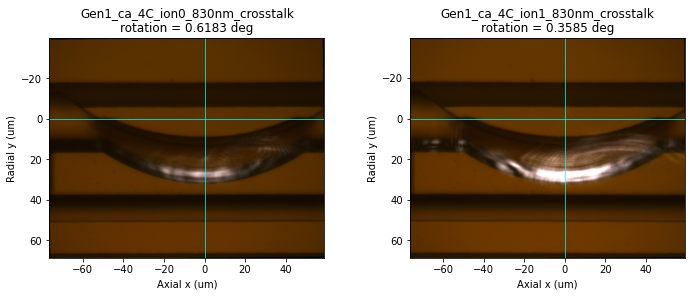

In [30]:
%matplotlib inline
preview_references(datasets, alignments)


## Process all datasets
Frames are read one at a time. Processed caches are invalidated when source files, the independent alignment, thresholds, or dark calibration change.

In [31]:
missing = set(datasets) - set(alignments)
if missing:
    raise RuntimeError(f"Complete the independent alignment cell first for ions {sorted(missing)}")
require_selected_wavelength(datasets, WAVELENGTH_NM)
stale_alignments = [ion for ion, dataset in datasets.items()
    if any(alignments[ion].get(key) != value for key, value in reference_signature(dataset).items())]
if stale_alignments:
    raise RuntimeError(f"Rerun alignment for {WAVELENGTH_NM} nm (ions {stale_alignments}) before processing.")
results = {}
for ion, dataset in datasets.items():
    results[ion] = process_dataset(dataset, alignments[ion], dark,
        signal_sigma_multiplier=SIGNAL_SIGMA_MULTIPLIER, max_rgb=MAX_RGB_CHANNEL, cache_dir=CACHE_DIR,
        excluded_exposures_ms=EXCLUDED_EXPOSURES_MS.get(ion, ()))

hdr_summary_all = pd.concat([r["summary"].assign(ion=ion, dataset=r["dataset"]["name"], wavelength_nm=WAVELENGTH_NM)
                            for ion, r in results.items()], ignore_index=True)
saturation_all = pd.concat([r["saturation"].assign(ion=ion, dataset=r["dataset"]["name"], wavelength_nm=WAVELENGTH_NM)
                            for ion, r in results.items()], ignore_index=True)
hdr_summary_all.to_csv(wavelength_output_path(OUTPUT_DIR, "hdr_peak_summary.csv", WAVELENGTH_NM), index=False)
saturation_all.to_csv(wavelength_output_path(OUTPUT_DIR, "short_exposure_saturation.csv", WAVELENGTH_NM), index=False)
display(hdr_summary_all.groupby(["ion", "dataset"]).agg(
    heights=("height_um", "size"), peaks_using_0p2_ms=("peak_uses_0p2_ms", "sum"),
    peak_rate_min=("peak_rate_counts_s", "min"), peak_rate_max=("peak_rate_counts_s", "max")))
display(saturation_all.groupby(["ion", "dataset"])["all_channels_below_sat"].all())


Gen1_ca_4C_ion0_830nm_crosstalk: 1/21 heights
Gen1_ca_4C_ion0_830nm_crosstalk: 5/21 heights
Gen1_ca_4C_ion0_830nm_crosstalk: 10/21 heights
Gen1_ca_4C_ion0_830nm_crosstalk: 15/21 heights
Gen1_ca_4C_ion0_830nm_crosstalk: 20/21 heights
Gen1_ca_4C_ion0_830nm_crosstalk: 21/21 heights
Gen1_ca_4C_ion1_830nm_crosstalk: 1/21 heights
Gen1_ca_4C_ion1_830nm_crosstalk: 5/21 heights
Gen1_ca_4C_ion1_830nm_crosstalk: 10/21 heights
Gen1_ca_4C_ion1_830nm_crosstalk: 15/21 heights
Gen1_ca_4C_ion1_830nm_crosstalk: 20/21 heights
Gen1_ca_4C_ion1_830nm_crosstalk: 21/21 heights


,,heights,peaks_using_0p2_ms,peak_rate_min,peak_rate_max
ion,dataset,,,,
0,Gen1_ca_4C_ion0_830nm_crosstalk,21,3,216048.578125,966848.50
1,Gen1_ca_4C_ion1_830nm_crosstalk,21,13,486109.312500,2725210.25


ion  dataset                        
0    Gen1_ca_4C_ion0_830nm_crosstalk    True
1    Gen1_ca_4C_ion1_830nm_crosstalk    True
Name: all_channels_below_sat, dtype: bool

## Peak count rate versus height
For each ion and every measured height, plot the maximum valid HDR count rate across the entire 2-D image. Rates are dark-corrected R+G+B counts divided by the actual exposure time in seconds. Each height uses its own peak location; the display and matrix y selections do not restrict this calculation. Figures remain inline.

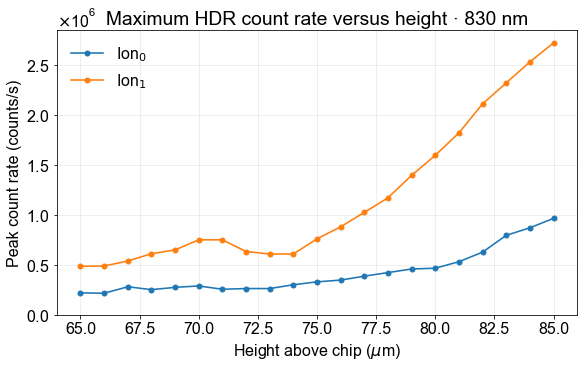

In [32]:
require_selected_wavelength(results, WAVELENGTH_NM)
# Global 2-D HDR peak at every measured height, independently for each ion.
# These are already dark-corrected RGB counts / actual exposure seconds.
# No fixed-y slice restriction, spatial averaging, or additional exposure normalization.
peak_count_rate_table = pd.concat([
    result["summary"][["height_um", "peak_rate_counts_s", "peak_x_um", "peak_y_um",
                       "peak_requested_exposure_ms"]].assign(ion=ion)
    for ion, result in sorted(results.items())
], ignore_index=True).sort_values(["ion", "height_um"])

with plt.rc_context({"font.family": "Arial", "font.size": 16}):
    fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
    for ion, table in peak_count_rate_table.groupby("ion", sort=True):
        ax.plot(table.height_um, table.peak_rate_counts_s, "o-", lw=1.6, ms=5,
                label=rf"Ion$_{{{int(ion)}}}$")
    ax.set(xlabel=r"Height above chip ($\mu$m)", ylabel="Peak count rate (counts/s)",
           title=f"Maximum HDR count rate versus height · {WAVELENGTH_NM} nm")
    ax.set_ylim(bottom=0)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    plt.show()
    plt.close(fig)


## HDR images, axial cuts, and exposure maps
The same exposure color is used across heights within each dataset. Set `PLOT_HEIGHTS_UM = None` to display all heights.

Choose the displayed axial cuts independently in Settings:
```python
HDR_SLICE_Y_UM = {0: None, 1: None}
# Example: {0: 18.0, 1: 25.5} selects fixed y coordinates (um).
```
A number chooses the nearest measured row; `None` follows that ion's brightest-pixel row at each height. Rerun Settings and the plot cell after changing these values. Cyan dashed lines mark the selected row on both images. The slice title reports the actual sampled y coordinate. The full HDR image uses its global peak for normalization; the axial slice uses its selected row's peak. This display setting is independent of the matrix and publication sampling.

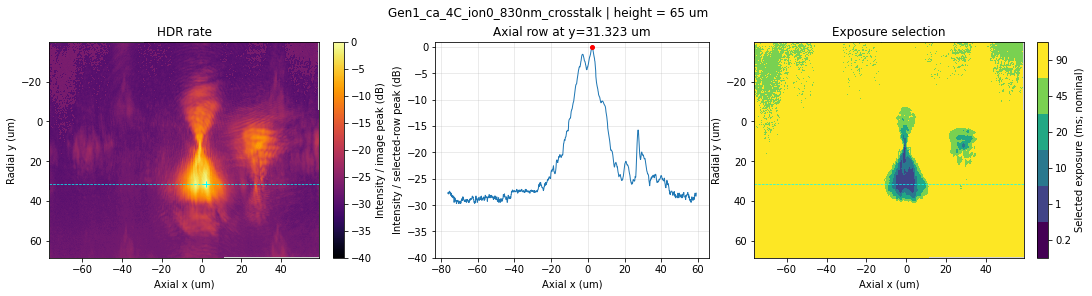

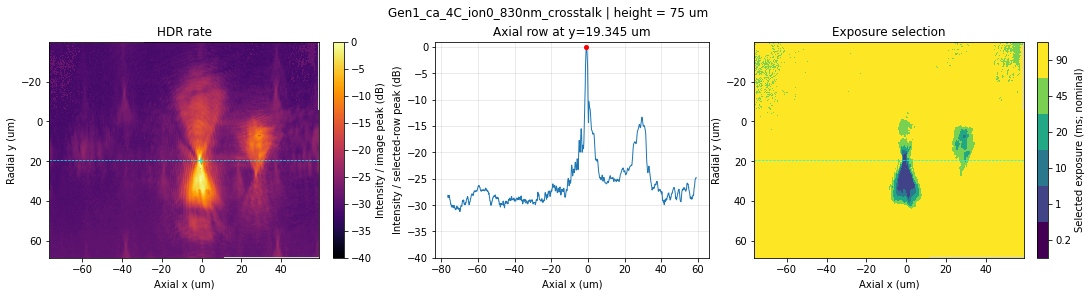

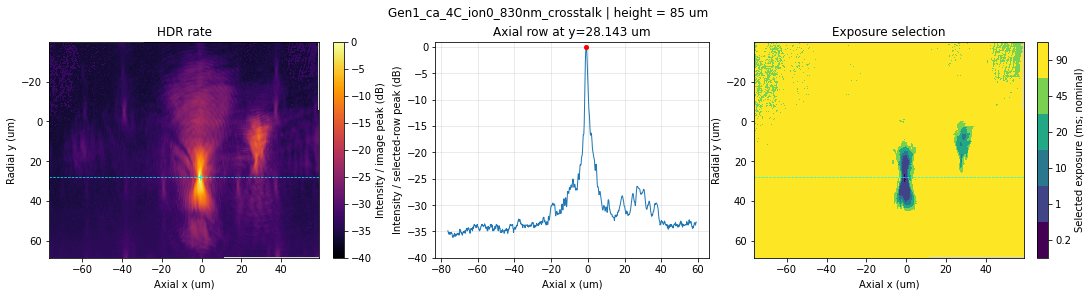

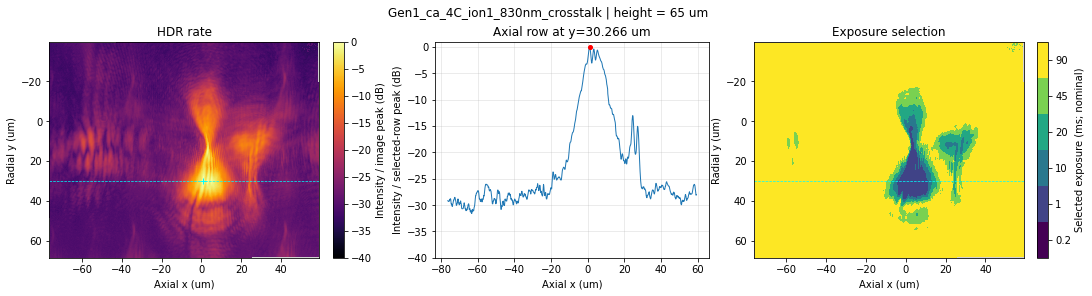

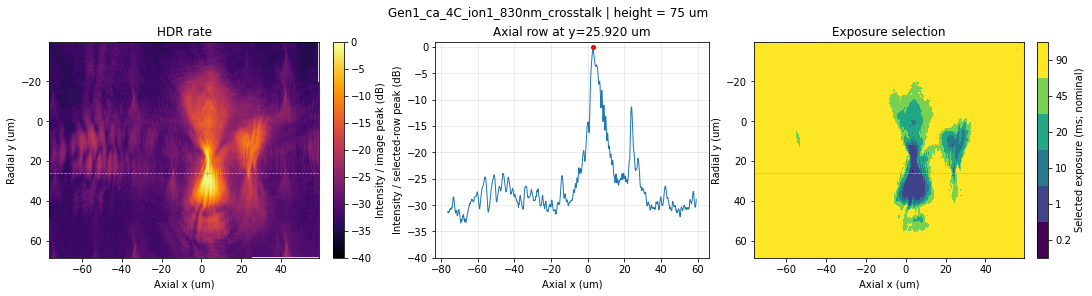

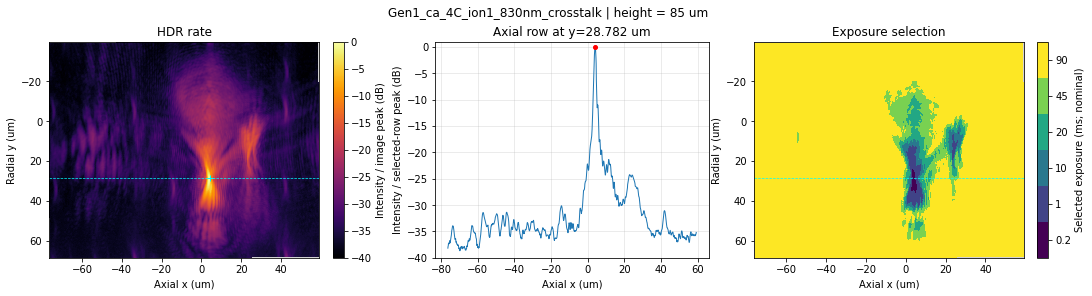

In [33]:
require_selected_wavelength(results, WAVELENGTH_NM)
# Choose each ion's displayed cut using HDR_SLICE_Y_UM in Settings.
# Example: {0: 18.0, 1: 25.5}; None follows the brightest row at each height.
for ion, result in results.items():
    slice_y_um = HDR_SLICE_Y_UM.get(ion) if isinstance(HDR_SLICE_Y_UM, dict) else HDR_SLICE_Y_UM
    plot_hdr(result, PLOT_HEIGHTS_UM, db_floor=DB_FLOOR, y_um=slice_y_um)


## Verify longest-valid HDR exposure selection
Production HDR now selects the **longest valid exposure** at every pixel, then normalizes its dark-corrected counts by actual exposure seconds. Exposure exclusions follow `EXCLUDED_EXPOSURES_MS`. Validity requires corrected counts strictly above the exposure-matched MANUAL 3σ threshold and every individual RGB channel below `MAX_RGB_CHANNEL`.

The comparison reconstructs the previous maximum-rate rule using the currently included frames. It verifies the production source map pixel by pixel against longest-valid selection at the chosen height. The rate plot checks exposure consistency in the same far-field ROI; the ROI is a diagnostic region, not a new dark calibration. All figures stay inline.

Ion 0: longest-valid HDR verified; far-field exposure percentages below.


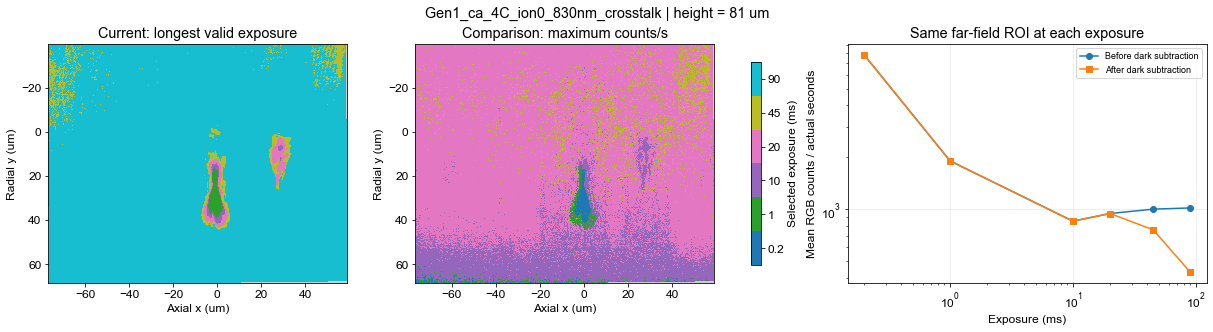

strategy,Comparison: maximum rate,Current: longest valid
exposure_ms,,
0.2,0.08,0.00
1.0,0.29,0.00
10.0,22.70,0.00
20.0,68.86,0.11
45.0,8.08,4.58
90.0,0.00,95.31


,point,x_um,y_um,exposure_ms,actual_exposure_ms,raw_counts,dark_counts,dark_std_counts,minimum_corrected_counts,corrected_counts,rate_counts_s,max_channel,valid,selected_current
0,2D peak,-0.936,25.069,0.2,0.2,118.0,0.000,3.576,10.729,118.000,591130.125,42,True,False
1,selected-row peak,-0.936,25.069,0.2,0.2,118.0,0.000,3.576,10.729,118.000,591130.125,42,True,False
2,"selected row, peak + 5 um",4.046,25.069,0.2,0.2,0.0,0.000,3.576,10.729,0.000,0.000,0,False,False
3,"selected row, peak + 25 um",24.080,25.069,0.2,0.2,0.0,0.000,3.576,10.729,0.000,0.000,0,False,False
4,2D peak,-0.936,25.069,1.0,1.0,532.0,0.000,3.585,10.755,532.000,532119.625,190,True,True
5,selected-row peak,-0.936,25.069,1.0,1.0,532.0,0.000,3.585,10.755,532.000,532119.625,190,True,True
6,"selected row, peak + 5 um",4.046,25.069,1.0,1.0,6.0,0.000,3.585,10.755,6.000,6001.350,2,False,False
7,"selected row, peak + 25 um",24.080,25.069,1.0,1.0,0.0,0.000,3.585,10.755,0.000,0.000,0,False,False
8,2D peak,-0.936,25.069,10.0,10.0,765.0,0.000,3.840,11.519,765.000,76500.000,255,False,False
9,selected-row peak,-0.936,25.069,10.0,10.0,765.0,0.000,3.840,11.519,765.000,76500.000,255,False,False


,exposure_ms,actual_exposure_ms,dark_counts,dark_std_counts,minimum_corrected_counts,raw_mean_counts,raw_mean_rate_counts_s,corrected_mean_rate_counts_s,valid_roi_percent
0,0.2,0.2,0.000,3.576,10.729,1.568,7853.700,7853.701,0.078
1,1.0,1.0,0.000,3.585,10.755,1.903,1903.483,1903.483,0.451
2,10.0,10.0,0.000,3.840,11.519,8.506,850.580,850.581,27.043
3,20.0,20.0,0.000,4.092,12.275,18.847,942.366,942.365,94.180
4,45.0,45.0,10.848,4.773,14.319,44.959,999.095,758.028,99.892
5,90.0,90.0,52.636,6.173,18.518,91.375,1015.277,430.428,95.314


Ion 1: longest-valid HDR verified; far-field exposure percentages below.


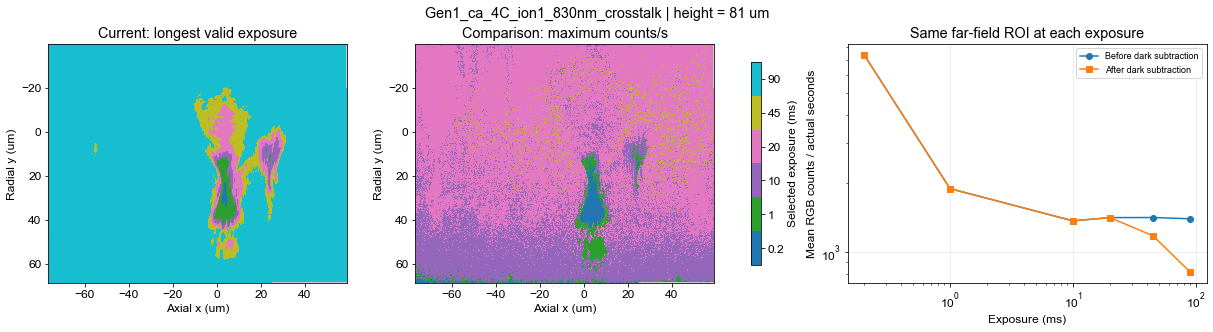

strategy,Comparison: maximum rate,Current: longest valid
exposure_ms,,
0.2,0.05,0.00
1.0,0.31,0.00
10.0,29.51,0.16
20.0,66.60,0.44
45.0,3.53,0.46
90.0,0.00,98.94


,point,x_um,y_um,exposure_ms,actual_exposure_ms,raw_counts,dark_counts,dark_std_counts,minimum_corrected_counts,corrected_counts,rate_counts_s,max_channel,valid,selected_current
0,2D peak,3.744,27.298,0.2,0.2,364.0,0.000,3.576,10.729,364.000,1823486.250,128,True,True
1,selected-row peak,3.744,27.298,0.2,0.2,364.0,0.000,3.576,10.729,364.000,1823486.250,128,True,True
2,"selected row, peak + 5 um",8.726,27.298,0.2,0.2,6.0,0.000,3.576,10.729,6.000,30057.465,2,False,False
3,"selected row, peak + 25 um",28.760,27.298,0.2,0.2,0.0,0.000,3.576,10.729,0.000,0.000,0,False,False
4,2D peak,3.744,27.298,1.0,1.0,765.0,0.000,3.585,10.755,765.000,765172.062,255,False,False
5,selected-row peak,3.744,27.298,1.0,1.0,765.0,0.000,3.585,10.755,765.000,765172.062,255,False,False
6,"selected row, peak + 5 um",8.726,27.298,1.0,1.0,34.0,0.000,3.585,10.755,34.000,34007.648,13,True,False
7,"selected row, peak + 25 um",28.760,27.298,1.0,1.0,0.0,0.000,3.585,10.755,0.000,0.000,0,False,False
8,2D peak,3.744,27.298,10.0,10.0,765.0,0.000,3.840,11.519,765.000,76500.000,255,False,False
9,selected-row peak,3.744,27.298,10.0,10.0,765.0,0.000,3.840,11.519,765.000,76500.000,255,False,False


,exposure_ms,actual_exposure_ms,dark_counts,dark_std_counts,minimum_corrected_counts,raw_mean_counts,raw_mean_rate_counts_s,corrected_mean_rate_counts_s,valid_roi_percent
0,0.2,0.2,0.000,3.576,10.729,1.471,7367.223,7367.223,0.048
1,1.0,1.0,0.000,3.585,10.755,1.898,1898.142,1898.142,0.923
2,10.0,10.0,0.000,3.840,11.519,13.698,1369.833,1369.833,45.054
3,20.0,20.0,0.000,4.092,12.275,28.315,1415.737,1415.735,99.668
4,45.0,45.0,10.848,4.773,14.319,63.742,1416.487,1175.420,99.401
5,90.0,90.0,52.636,6.173,18.518,125.929,1399.207,814.358,98.937


In [34]:
require_selected_wavelength(results, WAVELENGTH_NM)
HDR_AUDIT_HEIGHT_UM = 81.0
HDR_AUDIT_Y_UM = MATRIX_Y_UM
hdr_exposure_audits = {}
for ion, result in results.items():
    audit_y_um = HDR_AUDIT_Y_UM.get(ion) if isinstance(HDR_AUDIT_Y_UM, dict) else HDR_AUDIT_Y_UM
    audit = audit_hdr_exposure_selection(result, dark, HDR_AUDIT_HEIGHT_UM, audit_y_um)
    hdr_exposure_audits[ion] = audit
    print(f"Ion {ion}: longest-valid HDR verified; far-field exposure percentages below.")
    plot_hdr_exposure_audit(audit)
    display(audit["usage"].pivot(index="exposure_ms", columns="strategy", values="far_field_percent").round(2))
    display(audit["pixels"].round(3))
    display(audit["background"].round(3))


## Crosstalk at ±5 µm versus height
With `CROSSTALK_Y_UM = None`, each height uses one axial row through its brightest pixel. Both offsets are measured from that row’s peak and normalized to it.

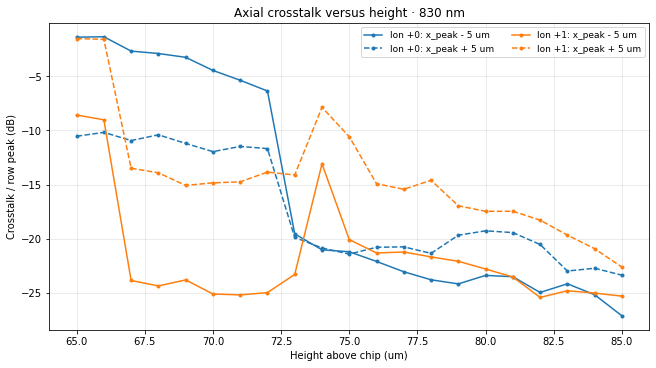

,height_um,peak_x_um,sample_y_um,peak_rate_counts_s,sample_x_minus_um,crosstalk_minus_db,sample_x_plus_um,crosstalk_plus_db,ion,wavelength_nm
0,65.0,2.243978,31.322778,2.200495e+05,-2.756022,-1.383027,7.243978,-10.533902,0,830
1,66.0,2.137978,30.580778,2.160486e+05,-2.862022,-1.343986,7.137978,-10.176913,0,830
2,67.0,1.819978,30.580778,2.810632e+05,-3.180022,-2.668627,6.819978,-10.932657,0,830
3,68.0,1.289978,29.944778,2.520567e+05,-3.710022,-2.891624,6.289978,-10.402160,0,830
4,69.0,1.183978,29.838778,2.750618e+05,-3.816022,-3.243191,6.183978,-11.194213,0,830
5,70.0,0.865978,29.414778,2.890650e+05,-4.134022,-4.453641,5.865978,-11.956437,0,830
6,71.0,0.653978,29.308778,2.560576e+05,-4.346022,-5.362487,5.653978,-11.476139,0,830
7,72.0,0.547978,29.414778,2.630592e+05,-4.452022,-6.355842,5.547978,-11.675439,0,830
8,73.0,-0.830022,18.284778,2.630592e+05,-5.830022,-19.554236,4.169978,-19.880740,0,830
9,74.0,-0.830022,18.814778,3.010677e+05,-5.830022,-21.024060,4.169978,-20.852538,0,830


In [35]:
require_selected_wavelength(results, WAVELENGTH_NM)
crosstalk_tables = {ion: crosstalk_by_height(result, CROSSTALK_OFFSET_UM, CROSSTALK_Y_UM)
                    for ion, result in results.items()}
crosstalk_all = pd.concat([table.assign(ion=ion, wavelength_nm=WAVELENGTH_NM) for ion, table in crosstalk_tables.items()],
                          ignore_index=True)
crosstalk_all.to_csv(wavelength_output_path(OUTPUT_DIR, "axial_offset_crosstalk.csv", WAVELENGTH_NM), index=False)
plot_crosstalk_scan(crosstalk_tables, CROSSTALK_OFFSET_UM, wavelength_nm=WAVELENGTH_NM)
display(crosstalk_all)


## Neighboring-ion crosstalk matrix
Set `MATRIX_HEIGHT_UM` and `MATRIX_Y_UM` in Settings. The radial cuts can be chosen independently:

```python
MATRIX_Y_UM = {0: 18.0, 1: 18.0}  # y coordinate in um for each driven ion
# Example: {0: 18.0, 1: None} fixes ion 0 and uses ion 1's brightest row.
```

Each numeric value selects that dataset's nearest measured radial row. `None` uses that dataset's own brightest-pixel row at every height. A shared scalar or `None` is also accepted. The axial peak and normalization are determined on the selected row.

Rows are measured-ion locations and columns are driven ions. Find the axial peak on each driven dataset's selected radial row, sample +5 µm for ion 0 → ion 1 or −5 µm for ion 1 → ion 0, and normalize to that same row's peak. All sampling uses nearest measured pixels. The requested and actual radial coordinates are recorded.

The matrix and height scan use this radial cut. Reference values in other figures match only when their radial cuts match. Diagonal entries are 0 dB when a valid peak is present.

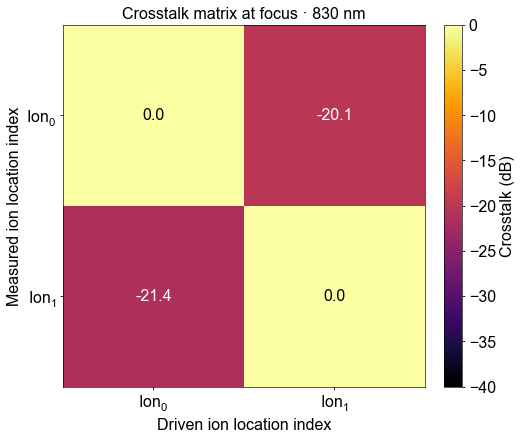

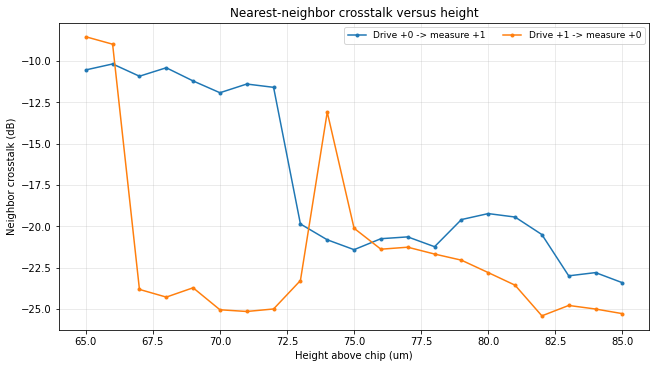

driven_ion,0,1
measured_ion,,
0,0.000000,-20.122148
1,-21.417031,0.000000


ion,0,1
height_um,,
65.0,2.243978,0.988091
66.0,2.137978,0.988091
67.0,1.819978,3.320091
68.0,1.289978,3.320091
69.0,1.183978,3.426091
70.0,0.865978,3.426091
71.0,0.653978,3.532091
72.0,0.547978,3.532091
73.0,-0.830022,3.532091


,driven_ion,requested_y_um,sample_y_um
0,0,None,31.322778
2,1,None,30.266197
4,0,None,30.580778
6,1,None,30.478197
10,1,None,15.320197
12,0,None,29.944778
14,1,None,15.426197
16,0,None,29.838778
18,1,None,15.850197
20,0,None,29.414778


In [36]:
require_selected_wavelength(results, WAVELENGTH_NM)
# Independent radial cuts in Settings: MATRIX_Y_UM = {0: 18.0, 1: 18.0}.
# Change each ion separately; None selects that driven ion's own brightest row at every height.
# Each column uses only its driven dataset and the axial peak/normalization on that selected row.
# Ca neighbor offsets: ion 0 -> +5 um; ion 1 -> -5 um. Use nearest measured pixels.
neighbor_scan = neighboring_matrices(results, y_um={0:None, 1:None}, pitch_um=ION_PITCH_UM,
                                    index_x_direction=ION_INDEX_X_DIRECTION)
neighbor_scan["wavelength_nm"] = int(WAVELENGTH_NM)
for table in (neighbor_scan["table"], neighbor_scan["peak_positions"]):
    table["wavelength_nm"] = int(WAVELENGTH_NM)
if neighbor_scan["mode"] != "driven_peak_nearest_pixel":
    raise RuntimeError("Rerun the HDR/axial-sampling/matrix function cell before this matrix cell.")
neighbor_scan["table"].to_csv(wavelength_output_path(OUTPUT_DIR, "neighbor_crosstalk_all_heights.csv", WAVELENGTH_NM), index=False)
neighbor_scan["peak_positions"].to_csv(wavelength_output_path(OUTPUT_DIR, "neighbor_peak_positions.csv", WAVELENGTH_NM), index=False)
plot_neighbor_matrix(neighbor_scan, MATRIX_HEIGHT_UM, DB_FLOOR,
                     font_family="Arial", font_size=16)
plot_neighbor_scan(neighbor_scan)
selected = neighbor_scan["table"][np.isclose(neighbor_scan["table"].height_um,
                                            MATRIX_HEIGHT_UM, rtol=0, atol=1e-4)]
display(selected.pivot(index="measured_ion", columns="driven_ion", values="crosstalk_db"))
display(neighbor_scan["peak_positions"].pivot(index="height_um", columns="ion", values="peak_x_um"))

display(neighbor_scan["table"][["driven_ion", "requested_y_um", "sample_y_um"]].drop_duplicates())


## Matrices at all common heights

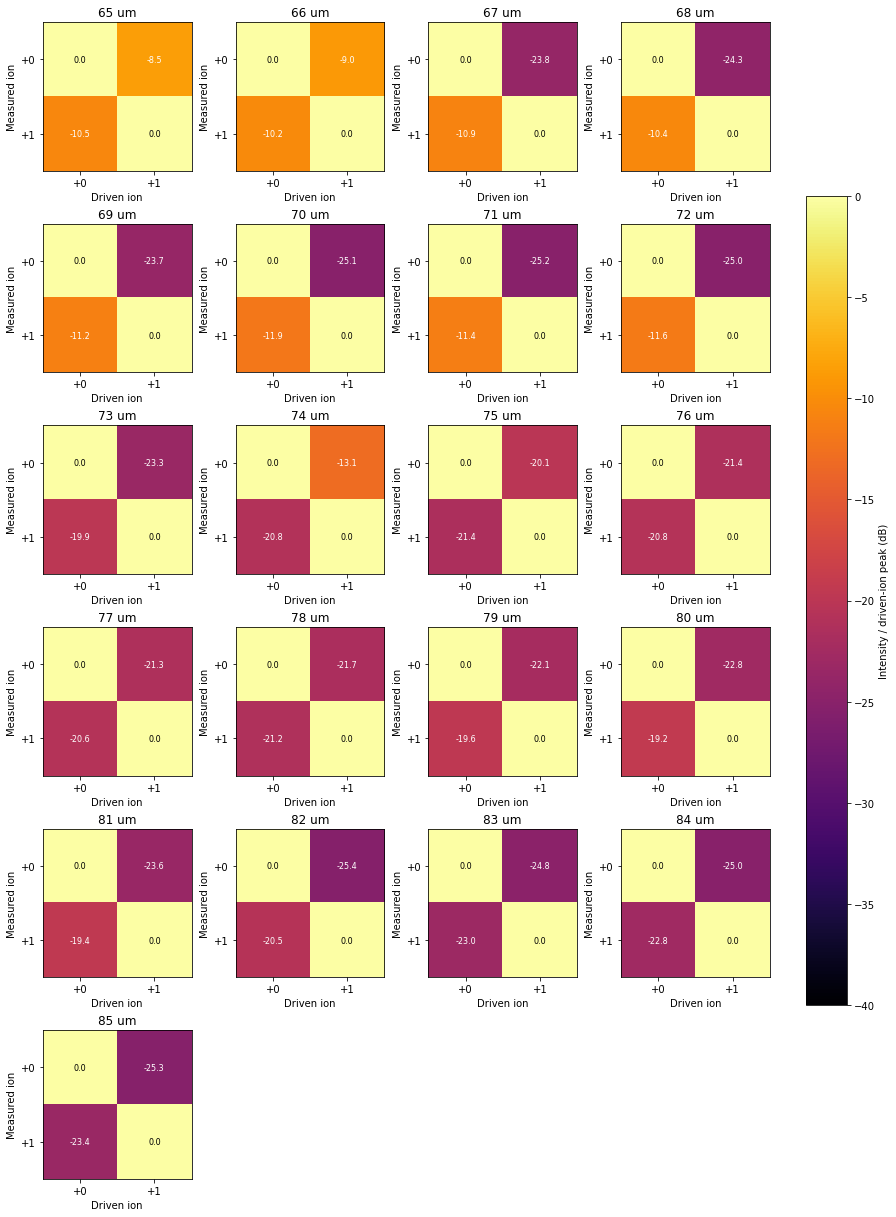

In [37]:
require_selected_wavelength(results, WAVELENGTH_NM)
require_scan_wavelength(neighbor_scan, WAVELENGTH_NM)
plot_matrix_grid(neighbor_scan, db_floor=DB_FLOOR)


## Publication analysis: reference at 75 µm
For each independently aligned ion, locate the brightest valid 2-D HDR pixel at 75 µm. Its radial coordinate defines Δy = 0. Sample heights from 65 to 85 µm in 1 µm steps and radial offsets from −5 to +5 µm in 1 µm steps around y₀.

At every (h, y), find the axial maximum xₚ(h, y), then calculate

$$C_{\Delta x}(h,y)=10\log_{10}\!\left[\frac{I_{\mathrm{HDR}}(x_p(h,y)+\Delta x,y,h)}{I_{\mathrm{HDR}}(x_p(h,y),y,h)}\right].$$

The Ca neighbor offsets are +5 µm for driven ion 0 and −5 µm for driven ion 1. This gives one neighbor map for each ion, two maps total.

For each nominal 1 µm radial and height target, select the closest measured row and height plane. Find the axial peak on that measured row, then select the closest measured axial pixel at each requested neighbor offset. No interpolation or smoothing is applied. Requested coordinates and actual sampled coordinates are both recorded; invalid sampled pixels remain missing.

In [38]:
require_selected_wavelength(results, WAVELENGTH_NM)
publication_scan = analyze_reference_windows(
    results, PUBLICATION_OFFSETS_UM,
    reference_height_um=PUBLICATION_REFERENCE_HEIGHT_UM,
    height_half_range_um=PUBLICATION_HEIGHT_HALF_RANGE_UM,
    radial_half_range_um=PUBLICATION_RADIAL_HALF_RANGE_UM,
    radial_step_um=PUBLICATION_RADIAL_STEP_UM,
    height_step_um=PUBLICATION_HEIGHT_STEP_UM,
    peak_search_half_width_um=PUBLICATION_PEAK_SEARCH_HALF_WIDTH_UM,
)
publication_scan["settings"]["wavelength_nm"] = int(WAVELENGTH_NM)
for table in (publication_scan["anchors"], publication_scan["baseline"]):
    table["wavelength_nm"] = int(WAVELENGTH_NM)
publication_scan["settings"]["ion_index_x_direction"] = ION_INDEX_X_DIRECTION
publication_scan["settings"]["ion_pitch_um"] = ION_PITCH_UM
publication_scan["settings"]["dark_calibration_path"] = str(DARK_PATH)
publication_scan["settings"]["dark_calibration_sha256"] = hashlib.sha256(DARK_PATH.read_bytes()).hexdigest()
publication_scan["settings"]["dark_processing_fingerprint"] = dark["fingerprint"]
publication_scan["settings"]["noise_calibration_path"] = str(NOISE_PATH)
publication_scan["settings"]["noise_calibration_fingerprint"] = dark["noise"]["fingerprint"]
publication_scan["settings"]["signal_sigma_multiplier"] = SIGNAL_SIGMA_MULTIPLIER
publication_scan["settings"]["dark_std_ddof"] = 1
publication_scan["settings"]["uncertainty_note"] = (
    "One signal frame per exposure/height. MANUAL SD is spatial across R+G+B pixel sums (ddof=1), not a temporal uncertainty or the error of the mean."
)
publication_quality = export_reference_windows(
    publication_scan, results, PUBLICATION_DIR, PUBLICATION_DB_LIMITS)
display(publication_scan["anchors"])
display(publication_scan["baseline"])
display(publication_quality)


,ion,dataset,reference_height_um,peak_x_um,peak_y_um,reference_peak_counts_s,reference_exposure_ms,reference_nominal_exposure_ms,native_radial_step_um,radial_samples,radial_sample_step_um,height_sample_step_um,wavelength_nm
0,0,Gen1_ca_4C_ion0_830nm_crosstalk,75.0,-0.830022,19.344778,330074.21875,0.999775,1.0,0.106,11,1.0,1.0,830
1,1,Gen1_ca_4C_ion1_830nm_crosstalk,75.0,3.002091,25.920197,761455.81250,0.199618,0.2,0.106,11,1.0,1.0,830


,ion,offset_um,height_um,peak_x_um,peak_y_um,target_x_um,sample_x_um,actual_offset_um,central_rate_counts_s,neighbor_rate_counts_s,crosstalk_linear,crosstalk_db,wavelength_nm
0,0,5.0,75.0,-0.830022,19.344778,4.169978,4.151978,4.982,330074.21875,2381.817627,0.007216,-21.417031,830
1,1,-5.0,75.0,3.002091,25.920197,-1.997909,-1.979909,-4.982,761455.81250,7403.376953,0.009723,-20.122148,830


,ion,offset_um,valid_samples,total_samples,valid_fraction,min_db,max_db,max_abs_peak_shift_um,samples_below_color_min,samples_above_color_max,wavelength_nm
0,0,5.0,231,231,1.0,-21.417031,-0.402946,3.074,0,0,830
1,1,-5.0,231,231,1.0,-26.206171,-2.992682,2.014,0,0,830


## Publication figures
Two reference axial slices and two Ca neighbor maps. White contours mark −20 dB. Sampling remains on the nominal 1 µm grid with nearest measured pixels, normal axis ticks, shared axis labels, and a shared −40 to 0 dB scale. The circled point marks the 75 µm reference. Figures display inline only.

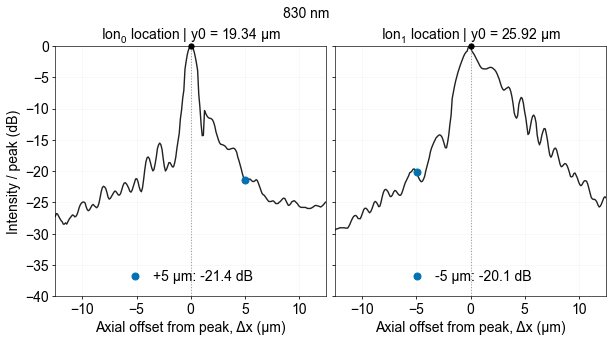

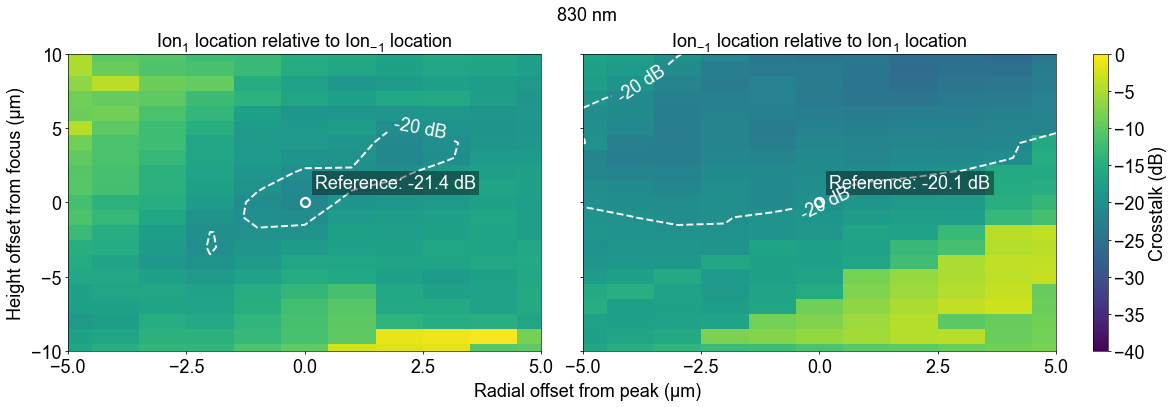

In [39]:
require_selected_wavelength(results, WAVELENGTH_NM)
require_scan_wavelength(publication_scan, WAVELENGTH_NM)
# Nearest-pixel sampling remains on a nominal 1 um radial and height grid.
# Axis tick spacing is independent of sampling; use normal ticks here.
PUBLICATION_DB_LIMITS = (-40.0, 0.0)
plot_reference_axial_profiles(publication_scan, db_limits=PUBLICATION_DB_LIMITS,
                              font_family="Arial", font_size=14)
plot_height_radial_maps(publication_scan, color_limits_db=PUBLICATION_DB_LIMITS,
                       contour_db=-20.0, font_family="Arial", font_size=18)


## Publication overlay with a nominal fixed-spacing reference
Both measured profiles retain their original axial coordinates and normalization to their own slice peaks. Dotted guides and markers are constrained to `COMMON_SLICE_REFERENCE_SPACING_UM` (default 5 µm), placed to maximize the weaker of the two normalized measured intensities. Linear interpolation is used only to evaluate marker positions between adjacent valid pixels. The Δx annotation reports this fixed reference spacing. Gaussian-center and measured-maximum separations remain available in the table/printed diagnostics; fit curves are not displayed. The subsequent crosstalk cell retains measured-maximum targets.

`COMMON_SLICE_MARKER_SHIFTS_UM` applies manual guide offsets after initial pair selection. The orange guide is shifted −0.1 µm, and the arrow reports the resulting 4.9 µm reference spacing.


Figure(680x460)
 ion  wavelength_nm  height_um  requested_y_um  sampled_y_um  slice_peak_x_um  slice_peak_rate_counts_s  fitted_center_x_um  gaussian_radius_um  gaussian_r_squared  gaussian_fit_half_width_um  reference_position_x_um  reference_normalized_intensity  reference_intensity_db  nominal_reference_spacing_um  display_reference_spacing_um
   0            830       75.0            19.5     19.450778        -0.830022              330074.21875           -0.799972            0.811052            0.991481                         4.0                -1.126753                        0.760087               -1.191364                           5.0                           4.9
   1            830       75.0            19.5     19.454197         3.532091              576129.56250            3.531074            0.859618            0.978181                         4.0                 3.773247                        0.886235               -0.524512                           5.0                

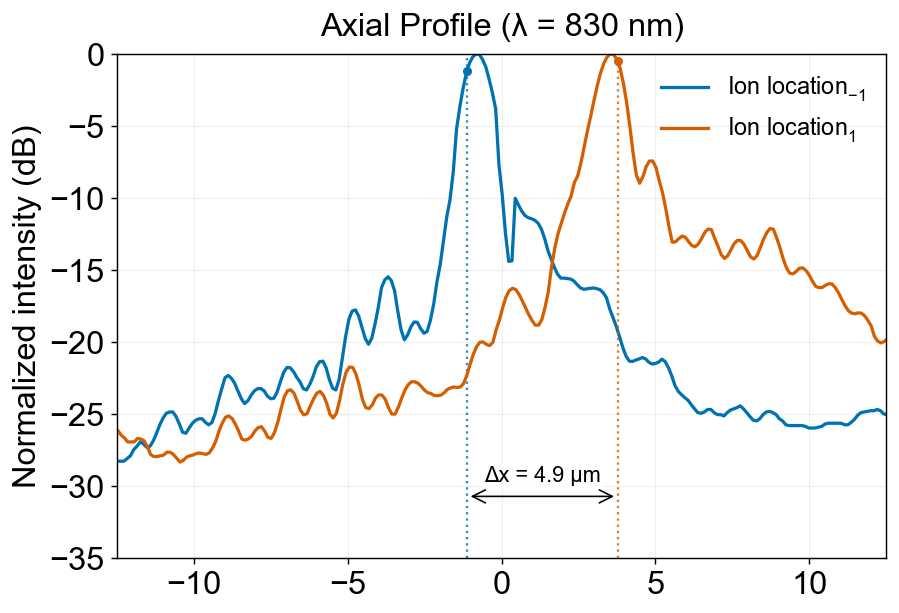

,ion,wavelength_nm,height_um,requested_y_um,sampled_y_um,slice_peak_x_um,slice_peak_rate_counts_s,fitted_center_x_um,gaussian_radius_um,gaussian_r_squared,gaussian_fit_half_width_um,reference_position_x_um,reference_normalized_intensity,reference_intensity_db,nominal_reference_spacing_um,display_reference_spacing_um
0,0,830,75.0,19.5,19.450778,-0.830022,330074.21875,-0.799972,0.811052,0.991481,4.0,-1.126753,0.760087,-1.191364,5.0,4.9
1,1,830,75.0,19.5,19.454197,3.532091,576129.56250,3.531074,0.859618,0.978181,4.0,3.773247,0.886235,-0.524512,5.0,4.9


In [3]:
# Overlay the two measured profiles on their existing trench-referenced axes.
# Measured profiles are not shifted; the displayed marker spacing is an explicit nominal reference.
COMMON_SLICE_Y_UM = 19.5
COMMON_SLICE_HEIGHT_UM = PUBLICATION_REFERENCE_HEIGHT_UM
COMMON_SLICE_X_LIMITS_UM = (-12.5, 12.5)
COMMON_SLICE_DB_LIMITS = (-35.0, 0.0)
COMMON_SLICE_FONT_SIZE = 18
COMMON_SLICE_REFERENCE_SPACING_UM = 5.0
COMMON_SLICE_MARKER_SHIFTS_UM = {1: -0.1}  # Orange guide: 0.1 um left of the initial reference.
COMMON_SLICE_FIT_HALF_WIDTH_UM = 4.0  # Gaussian + constant background, fitted in linear intensity.
# Manuscript wavelength label; acquisition metadata remain unchanged.
COMMON_SLICE_TITLE_WAVELENGTH_NM = 730 if WAVELENGTH_NM == 729 else WAVELENGTH_NM
COMMON_SLICE_SEPARATION_Y_DB = -30.7  # Text sits at -30 dB.

def place_fixed_spacing_markers(left_x, left_intensity, right_x, right_intensity,
                                spacing_um=5.0, x_limits=None):
    """Maximize the weaker of two measured intensities at positions x and x+d.

    Interpolate linear intensity only between adjacent valid measured pixels.
    For piecewise-linear profiles, the global maximin is at a profile knot or
    an intersection, so inspect both exactly without shifting either profile.
    """
    left_x, right_x = np.asarray(left_x, dtype=float), np.asarray(right_x, dtype=float)
    left_intensity = np.asarray(left_intensity, dtype=float)
    right_intensity = np.asarray(right_intensity, dtype=float)
    for x, values in ((left_x, left_intensity), (right_x, right_intensity)):
        if (x.ndim != 1 or values.shape != x.shape or len(x) < 2
                or not np.isfinite(x).all() or np.any(np.diff(x) <= 0)):
            raise ValueError("Each profile needs matching intensities and increasing finite coordinates.")
    if not np.isfinite(spacing_um) or spacing_um <= 0:
        raise ValueError("Reference spacing must be positive and finite.")
    lo = max(float(left_x[0]), float(right_x[0])-spacing_um)
    hi = min(float(left_x[-1]), float(right_x[-1])-spacing_um)
    if x_limits is not None:
        lo = max(lo, float(x_limits[0]))
        hi = min(hi, float(x_limits[1])-spacing_um)
    if lo >= hi:
        raise ValueError("The profiles do not overlap at the requested spacing.")
    knots = np.unique(np.r_[lo, hi, left_x, right_x-spacing_um])
    knots = knots[(knots >= lo) & (knots <= hi)]

    def evaluate(position):
        return np.array([
            sample_linear(left_x, left_intensity, position),
            sample_linear(right_x, right_intensity, position+spacing_um),
        ])

    values = np.array([evaluate(position) for position in knots])
    candidates = [(float(position), value) for position, value in zip(knots, values)
                  if np.isfinite(value).all()]
    for index in range(len(knots)-1):
        pair = values[index:index+2]
        if not np.isfinite(pair).all():
            continue
        differences = pair[:, 0]-pair[:, 1]
        if differences[0]*differences[1] < 0:
            fraction = differences[0]/(differences[0]-differences[1])
            position = knots[index]+fraction*(knots[index+1]-knots[index])
            value = evaluate(position)
            if np.isfinite(value).all():
                candidates.append((float(position), value))
    if not candidates:
        raise ValueError("No valid pair of measured intensities at this spacing.")
    # First maximize the weaker beam; use the sum only to break ties.
    position, value = max(candidates, key=lambda candidate: (float(candidate[1].min()),
                                                           float(candidate[1].sum())))
    return dict(left_x_um=position, right_x_um=position+spacing_um,
                left_normalized_intensity=float(value[0]),
                right_normalized_intensity=float(value[1]),
                weaker_normalized_intensity=float(value.min()),
                spacing_um=float(spacing_um))


require_selected_wavelength(results, WAVELENGTH_NM)
if set(results) != {0, 1}:
    raise ValueError("This comparison requires the two driven-ion datasets, 0 and 1.")

from Analysis.Experimental_Analysis import Experimental_Analysis

common_slice_profiles = {}
common_slice_gaussian_fits = {}
common_slice_records = []
for ion, result in sorted(results.items()):
    slot = height_slot(result, COMMON_SLICE_HEIGHT_UM)
    profile, peak_x, sampled_y, peak_rate = axial_profile(
        result, slot, y_um=COMMON_SLICE_Y_UM,
    )
    if not np.isfinite(peak_rate) or peak_rate <= 0:
        raise ValueError(f"Ion {ion}: no valid signal on the selected radial slice.")
    x = result["x_um"]
    if not COMMON_SLICE_X_LIMITS_UM[0] <= peak_x <= COMMON_SLICE_X_LIMITS_UM[1]:
        raise ValueError(f"Ion {ion}: expand COMMON_SLICE_X_LIMITS_UM to include its peak.")
    db = np.full(profile.shape, np.nan)
    valid = np.isfinite(profile) & (profile > 0)
    db[valid] = 10*np.log10(profile[valid]/peak_rate)
    try:
        gaussian_fit = Experimental_Analysis.fit_gaussian_profile(
            x, profile, half_width_um=COMMON_SLICE_FIT_HALF_WIDTH_UM,
        )
    except (ValueError, RuntimeError) as error:
        raise RuntimeError(f"Ion {ion}: axial Gaussian fit failed: {error}") from error
    if not gaussian_fit["half_max_covered"]:
        raise ValueError(f"Ion {ion}: widen COMMON_SLICE_FIT_HALF_WIDTH_UM to cover the Gaussian peak.")
    common_slice_gaussian_fits[ion] = gaussian_fit
    common_slice_profiles[ion] = dict(
        x_um=x, db=db, normalized_intensity=profile/peak_rate, peak_x_um=peak_x,
        fitted_center_x_um=gaussian_fit["center_um"],
    )
    common_slice_records.append(dict(
        ion=ion, wavelength_nm=WAVELENGTH_NM, height_um=COMMON_SLICE_HEIGHT_UM,
        requested_y_um=COMMON_SLICE_Y_UM, sampled_y_um=sampled_y,
        slice_peak_x_um=peak_x, slice_peak_rate_counts_s=peak_rate,
        fitted_center_x_um=gaussian_fit["center_um"],
        gaussian_radius_um=gaussian_fit["radius_um"],
        gaussian_r_squared=gaussian_fit["r_squared"],
        gaussian_fit_half_width_um=COMMON_SLICE_FIT_HALF_WIDTH_UM,
    ))

common_slice_table = pd.DataFrame(common_slice_records)
common_slice_peak_separation_um = abs(
    common_slice_profiles[1]["peak_x_um"] - common_slice_profiles[0]["peak_x_um"]
)
common_slice_separation_um = abs(
    common_slice_profiles[1]["fitted_center_x_um"] - common_slice_profiles[0]["fitted_center_x_um"]
)
# Place a fixed-spacing pair on the measured profiles, maximizing the weaker
# normalized intensity. Linear interpolation locates the markers between valid
# measured pixels; it does not shift or resample the displayed curves.
left_ion, right_ion = sorted(common_slice_profiles,
                             key=lambda ion: common_slice_profiles[ion]["peak_x_um"])
left_profile, right_profile = common_slice_profiles[left_ion], common_slice_profiles[right_ion]
common_slice_fixed_spacing = place_fixed_spacing_markers(
    left_profile["x_um"], left_profile["normalized_intensity"],
    right_profile["x_um"], right_profile["normalized_intensity"],
    spacing_um=COMMON_SLICE_REFERENCE_SPACING_UM, x_limits=COMMON_SLICE_X_LIMITS_UM,
)
for ion, side in ((left_ion, "left"), (right_ion, "right")):
    reference_x = (common_slice_fixed_spacing[f"{side}_x_um"]
                   + COMMON_SLICE_MARKER_SHIFTS_UM.get(ion, 0.0))
    reference_intensity = sample_linear(
        common_slice_profiles[ion]["x_um"], common_slice_profiles[ion]["normalized_intensity"], reference_x)
    if not np.isfinite(reference_intensity):
        raise ValueError(f"Ion {ion}: shifted guide has no valid intensity at its requested position.")
    common_slice_profiles[ion]["reference_position_x_um"] = reference_x
    common_slice_profiles[ion]["reference_normalized_intensity"] = reference_intensity
    mask = common_slice_table.ion == ion
    common_slice_table.loc[mask, "reference_position_x_um"] = reference_x
    common_slice_table.loc[mask, "reference_normalized_intensity"] = reference_intensity
    common_slice_table.loc[mask, "reference_intensity_db"] = 10*np.log10(reference_intensity)
common_slice_table["nominal_reference_spacing_um"] = COMMON_SLICE_REFERENCE_SPACING_UM
common_slice_display_reference_spacing_um = (
    common_slice_profiles[right_ion]["reference_position_x_um"]
    - common_slice_profiles[left_ion]["reference_position_x_um"])
common_slice_table["display_reference_spacing_um"] = common_slice_display_reference_spacing_um

with plt.rc_context({
    "font.family": "Arial", "font.size": COMMON_SLICE_FONT_SIZE,
    "axes.labelsize": COMMON_SLICE_FONT_SIZE,
    "xtick.labelsize": 18, "ytick.labelsize": 18,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "text.color": "black", "axes.labelcolor": "black",
    "axes.edgecolor": "black", "xtick.color": "black", "ytick.color": "black",
    "svg.fonttype": "none",
    "mathtext.fontset": "custom", "mathtext.rm": "Arial",
    "mathtext.it": "Arial:italic", "mathtext.bf": "Arial:bold",
}):
    if "common_slice_figure" in globals():
        plt.close(common_slice_figure)
    common_slice_figure, ax = plt.subplots(figsize=(6.8, 4.6), constrained_layout=True)
    for ion, color, style in ((0, "#0072B2", "-"), (1, "#D55E00", "-")):
        profile = common_slice_profiles[ion]
        ax.plot(profile["x_um"], profile["db"], color=color, ls=style, lw=1.8,
                label=rf"Ion location$_{{{-1 if ion == 0 else 1}}}$")
        # Reference guides include requested manual offsets; markers lie on measured profiles.
        ax.axvline(profile["reference_position_x_um"], color=color, ls=":", lw=1.3, alpha=0.8)
        ax.plot(profile["reference_position_x_um"],
                10*np.log10(profile["reference_normalized_intensity"]),
                "o", color=color, ms=4, zorder=4)
    left_peak = common_slice_profiles[left_ion]["reference_position_x_um"]
    right_peak = common_slice_profiles[right_ion]["reference_position_x_um"]
    ax.annotate("", xy=(left_peak, COMMON_SLICE_SEPARATION_Y_DB),
                xytext=(right_peak, COMMON_SLICE_SEPARATION_Y_DB),
                arrowprops=dict(arrowstyle="<->", color="black", lw=0.9))
    ax.text((left_peak+right_peak)/2, COMMON_SLICE_SEPARATION_Y_DB+0.7, f"Δx = {common_slice_display_reference_spacing_um:.1f} µm",
            ha="center", va="bottom", fontsize=12,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.9, pad=1.5))
    ax.set(xlim=COMMON_SLICE_X_LIMITS_UM, ylim=COMMON_SLICE_DB_LIMITS,
           xticks=[-10, -5, 0, 5, 10], yticks=np.arange(-35, 1, 5),
           xlabel="", ylabel="Normalized intensity (dB)")
    ax.set_title(
        f"Axial Profile (λ = {COMMON_SLICE_TITLE_WAVELENGTH_NM} nm)",
        fontfamily="Arial", fontsize=18, pad=10,
    )
    ax.grid(alpha=0.18, lw=0.6)
    ax.legend(frameon=False, fontsize=13, loc="upper right")
    display(common_slice_figure)
    plt.close(common_slice_figure)

# The nearest measured rows can differ by a fraction of a camera pixel.
# Separation is in the existing independently selected trench coordinate frames.
display(common_slice_table)
print(f"Gaussian-center separation: {common_slice_separation_um:.3f} µm "
      f"(measured-maximum separation: {common_slice_peak_separation_um:.3f} µm).")

print(f"Nominal markers: x = {common_slice_fixed_spacing['left_x_um']:.3f}, "
      f"{common_slice_fixed_spacing['right_x_um']:.3f} µm; "
      f"normalized intensities = {common_slice_fixed_spacing['left_normalized_intensity']:.3f}, "
      f"{common_slice_fixed_spacing['right_normalized_intensity']:.3f}.")

# Export the measured blue profile with its own maximum at x = 0 for the fluorescence map.
blue_peak_profile_export = pd.DataFrame(dict(
    x_from_peak_um=common_slice_profiles[0]["x_um"]-common_slice_profiles[0]["peak_x_um"],
    x_original_um=common_slice_profiles[0]["x_um"],
    normalized_intensity=common_slice_profiles[0]["normalized_intensity"],
    normalized_intensity_db=common_slice_profiles[0]["db"],
))
blue_peak_profile_export["peak_x_original_um"] = common_slice_profiles[0]["peak_x_um"]
blue_peak_profile_export["wavelength_nm"] = WAVELENGTH_NM
blue_peak_profile_export["height_um"] = COMMON_SLICE_HEIGHT_UM
blue_peak_profile_export["requested_y_um"] = COMMON_SLICE_Y_UM
blue_peak_export_dir = OUTPUT_DIR / "publication_common_y"
blue_peak_export_dir.mkdir(parents=True, exist_ok=True)
blue_peak_export_path = blue_peak_export_dir / (
    f"blue_peak_profile_{WAVELENGTH_NM}nm_y{COMMON_SLICE_Y_UM:g}um_h{COMMON_SLICE_HEIGHT_UM:g}um.csv")
blue_peak_profile_export.to_csv(blue_peak_export_path, index=False)
print(f"Exported peak-referenced blue profile: {blue_peak_export_path}")

# Export the orange profile on its own measured-peak origin for the mirrored 5 um window.
orange_peak_profile_export = pd.DataFrame(dict(
    x_from_peak_um=common_slice_profiles[1]["x_um"]-common_slice_profiles[1]["peak_x_um"],
    x_original_um=common_slice_profiles[1]["x_um"],
    normalized_intensity=common_slice_profiles[1]["normalized_intensity"],
    normalized_intensity_db=common_slice_profiles[1]["db"],
))
orange_peak_profile_export["peak_x_original_um"] = common_slice_profiles[1]["peak_x_um"]
orange_peak_profile_export["wavelength_nm"] = WAVELENGTH_NM
orange_peak_profile_export["height_um"] = COMMON_SLICE_HEIGHT_UM
orange_peak_profile_export["requested_y_um"] = COMMON_SLICE_Y_UM
orange_peak_export_path = blue_peak_export_dir / (
    f"orange_peak_profile_{WAVELENGTH_NM}nm_y{COMMON_SLICE_Y_UM:g}um_h{COMMON_SLICE_HEIGHT_UM:g}um.csv")
orange_peak_profile_export.to_csv(orange_peak_export_path, index=False)
print(f"Exported peak-referenced orange profile: {orange_peak_export_path}")


## End-to-end intensity ratio as a 5 µm window slides
Both ends move together: `x_L = x_L0 + δ`, `x_R = x_L + 5 µm`. Offset zero uses the balanced exact-5-µm reference pair before the upper figure's manual guide adjustment. Positive offsets move the window right.

For the **blue (−1) curve**, plot `10 log10[I_blue(x_R) / I_blue(x_L)]`. For the **orange (+1) curve**, plot `10 log10[I_orange(x_L) / I_orange(x_R)]`. Both numerator and denominator change as the window slides. The profile's initial peak-normalization factor cancels; the peak is not the denominator. −5 dB means that the off-site endpoint has 31.6% of the intensity at the on-site endpoint. Positive ratios in dB mean the off-site endpoint is stronger.

Interpolate linear intensity only between adjacent valid HDR pixels, without smoothing or bridging gaps. Threshold crossings are solved between the combined breakpoints of both moving samples. The 0.01 µm display step does not increase the native spatial resolution. All crossings and both endpoint intensities are exported.


Figure(820x520)
Offset 0: exact 5 µm pair at x = -1.127, 3.873 µm. Positive offset moves both markers right.
Each ratio compares that same curve at BOTH moving window ends: blue right/left; orange left/right.
 driven_location  measured_location  axial_offset_um  left_marker_x_um  right_marker_x_um  crosstalk_db  opposite_direction_db
              -1                  1        -0.663028         -1.789781           3.210219          -5.0             -21.973355
               1                 -1         1.512369          0.385616           5.385616          -5.0              -9.821271
Ion -1 → +1: -5 dB at offset -0.663 µm; opposite direction = -21.97 dB.
Ion +1 → -1: -5 dB at offset +1.512 µm; opposite direction = -9.82 dB.
Saved: /Users/yiyangzhi/GIT/integrated_trapped_ions/Gen_1_Paper/cross_talk_results_ca/publication_common_y/window_end_ratio_830nm_y19.5um_h75um.svg


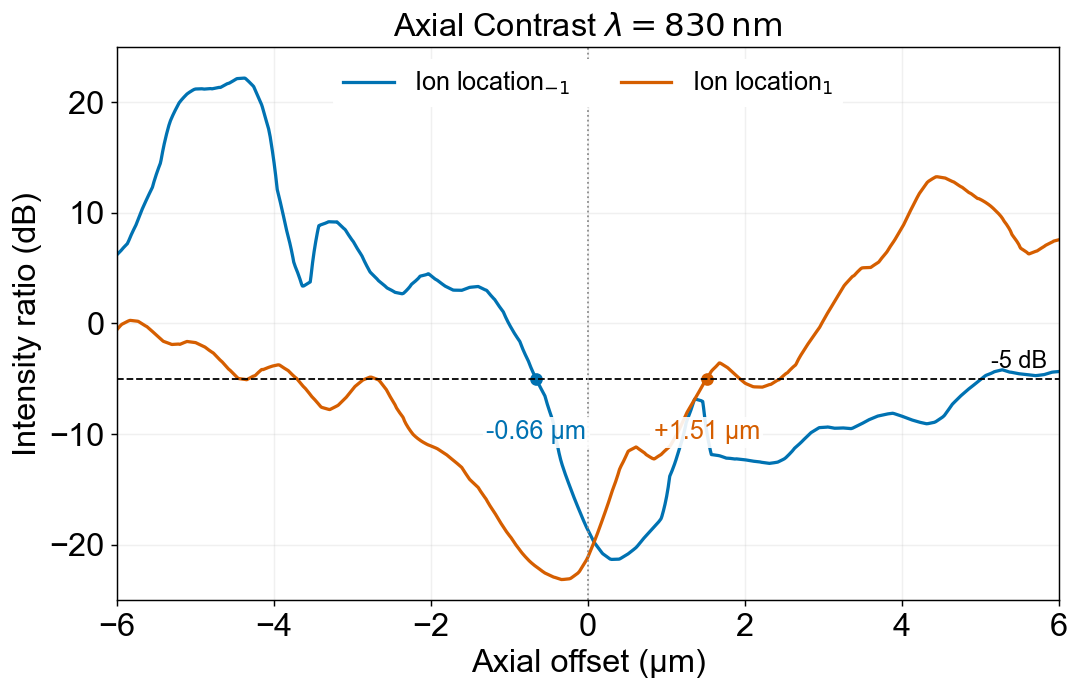

,driven_location,measured_location,axial_offset_um,left_marker_x_um,right_marker_x_um,crosstalk_db,opposite_direction_db
0,-1,1,-0.663028,-1.789781,3.210219,-5.0,-21.973355
7,1,-1,1.512369,0.385616,5.385616,-5.0,-9.821271


In [4]:
# Slide an exact 5 um window and compare each curve at its two moving ends.
MARKER_SCAN_SPACING_UM = 5.0
MARKER_SCAN_OFFSET_LIMITS_UM = (-6.0, 6.0)
MARKER_SCAN_STEP_UM = 0.01  # Display sampling only; threshold crossings are solved on measured segments.
MARKER_SCAN_TARGET_DB = -5.0


def marker_shift_crosstalk_scan(profiles, left_ion, right_ion, left_x_um, spacing_um,
                                offsets_um, target_db=-5.0):
    """Compare the two ends of each curve's moving fixed-width window.

    Left-channel crosstalk is I(right)/I(left); right-channel crosstalk is
    I(left)/I(right). The numerator AND denominator move with the window.
    Linear interpolation is restricted to adjacent valid positive HDR pixels.
    Solve numerator - threshold*denominator = 0 on the union of their shifted
    pixel breakpoints; this is linear on each valid segment, independent of
    the display sampling grid. No peak normalization enters the final ratio.
    """
    offsets = np.asarray(offsets_um, dtype=float)
    if (left_ion == right_ion or set(profiles) != {left_ion, right_ion}
            or offsets.ndim != 1 or len(offsets) < 2
            or not np.isfinite(offsets).all() or np.any(np.diff(offsets) <= 0)
            or not np.isfinite([left_x_um, spacing_um, target_db]).all() or spacing_um <= 0):
        raise ValueError("Require two profiles, increasing finite offsets, and positive marker spacing")
    reference_positions = {left_ion: float(left_x_um), right_ion: float(left_x_um+spacing_um)}
    scan_records, crossing_records = [], []
    threshold = float(10**(target_db/10))
    for driven, measured in ((left_ion, right_ion), (right_ion, left_ion)):
        profile = profiles[driven]
        x = np.asarray(profile["x_um"], dtype=float)
        values = np.asarray(profile["normalized_intensity"], dtype=float)
        if (x.ndim != 1 or values.shape != x.shape or len(x) < 2
                or not np.isfinite(x).all() or np.any(np.diff(x) <= 0)):
            raise ValueError("Each profile needs matching intensities and increasing finite coordinates")
        own_reference_x = reference_positions[driven]
        target_reference_x = reference_positions[measured]

        def endpoints(offset):
            numerator = sample_linear(x, values, target_reference_x+offset)
            denominator = sample_linear(x, values, own_reference_x+offset)
            return numerator, denominator

        for offset in offsets:
            numerator, denominator = endpoints(offset)
            good = np.isfinite([numerator, denominator]).all() and min(numerator, denominator) > 0
            ratio = float(numerator/denominator) if good else np.nan
            scan_records.append(dict(driven_ion=driven, measured_ion=measured,
                axial_offset_um=float(offset),
                left_marker_x_um=reference_positions[left_ion]+float(offset),
                right_marker_x_um=reference_positions[right_ion]+float(offset),
                sample_x_um=float(target_reference_x+offset), own_marker_x_um=float(own_reference_x+offset),
                offsite_intensity=numerator, onsite_intensity=denominator,
                intensity_ratio=ratio, crosstalk_db=ratio_db(numerator, denominator)))

        breakpoints = np.unique(np.r_[offsets[0], offsets[-1],
            x-target_reference_x, x-own_reference_x])
        breakpoints = breakpoints[(breakpoints >= offsets[0]) & (breakpoints <= offsets[-1])]
        roots = []
        for a, b in zip(breakpoints[:-1], breakpoints[1:]):
            na, da = endpoints(a)
            nb, db = endpoints(b)
            if not np.isfinite([na, da, nb, db]).all() or min(na, da, nb, db) <= 0:
                continue
            fa, fb = na-threshold*da, nb-threshold*db
            if np.isclose(fa, 0, rtol=0, atol=1e-12):
                roots.append(float(a))
            if np.isclose(fb, 0, rtol=0, atol=1e-12):
                roots.append(float(b))
            if fa*fb < 0:
                roots.append(float(a-fa*(b-a)/(fb-fa)))
            elif np.isclose(fa, 0, rtol=0, atol=1e-12) and np.isclose(fb, 0, rtol=0, atol=1e-12):
                roots.append(float(np.clip(0., a, b)))
        roots = sorted(set(round(root, 12) for root in roots))
        for offset in roots:
            numerator, denominator = endpoints(offset)
            if not np.isfinite([numerator, denominator]).all() or min(numerator, denominator) <= 0:
                continue
            crossing_records.append(dict(driven_ion=driven, measured_ion=measured,
                axial_offset_um=offset, sample_x_um=target_reference_x+offset,
                own_marker_x_um=own_reference_x+offset,
                left_marker_x_um=reference_positions[left_ion]+offset,
                right_marker_x_um=reference_positions[right_ion]+offset,
                offsite_intensity=numerator, onsite_intensity=denominator,
                crosstalk_db=ratio_db(numerator, denominator), intensity_ratio=numerator/denominator))
    columns = ["driven_ion", "measured_ion", "axial_offset_um", "sample_x_um", "own_marker_x_um",
               "left_marker_x_um", "right_marker_x_um", "offsite_intensity", "onsite_intensity",
               "crosstalk_db", "intensity_ratio"]
    return pd.DataFrame(scan_records), pd.DataFrame(crossing_records, columns=columns)

if "common_slice_profiles" not in globals() or "common_slice_table" not in globals():
    raise RuntimeError("Run the axial-profile cell immediately above first")
if (set(common_slice_table.wavelength_nm.astype(int)) != {int(WAVELENGTH_NM)}
        or not np.allclose(common_slice_table.height_um, COMMON_SLICE_HEIGHT_UM)
        or not np.allclose(common_slice_table.requested_y_um, COMMON_SLICE_Y_UM)):
    raise RuntimeError("The profiles belong to different settings; rerun the axial-profile cell above")
if not np.isfinite(MARKER_SCAN_STEP_UM) or MARKER_SCAN_STEP_UM <= 0:
    raise ValueError("MARKER_SCAN_STEP_UM must be positive and finite")
if (not np.isfinite(MARKER_SCAN_OFFSET_LIMITS_UM).all()
        or MARKER_SCAN_OFFSET_LIMITS_UM[0] >= MARKER_SCAN_OFFSET_LIMITS_UM[1]):
    raise ValueError("Specify increasing finite marker-offset limits")

# Start from the brightest balanced exact-5-um pair, before the upper figure's manual guide offsets.
marker_scan_reference = place_fixed_spacing_markers(
    common_slice_profiles[left_ion]["x_um"], common_slice_profiles[left_ion]["normalized_intensity"],
    common_slice_profiles[right_ion]["x_um"], common_slice_profiles[right_ion]["normalized_intensity"],
    spacing_um=MARKER_SCAN_SPACING_UM, x_limits=COMMON_SLICE_X_LIMITS_UM)
marker_scan_offsets = np.linspace(*MARKER_SCAN_OFFSET_LIMITS_UM,
    int(np.ceil(np.ptp(MARKER_SCAN_OFFSET_LIMITS_UM)/MARKER_SCAN_STEP_UM))+1)
marker_offset_crosstalk, marker_offset_crossings = marker_shift_crosstalk_scan(
    common_slice_profiles, left_ion, right_ion, marker_scan_reference["left_x_um"],
    MARKER_SCAN_SPACING_UM, marker_scan_offsets, MARKER_SCAN_TARGET_DB)

for marker_table in (marker_offset_crosstalk, marker_offset_crossings):
    marker_table["driven_location"] = marker_table.driven_ion.map({0: -1, 1: 1})
    marker_table["measured_location"] = marker_table.measured_ion.map({0: -1, 1: 1})

# Report the closest crossing to zero for each direction, retaining all crossings in the CSV.
marker_offset_nearest_crossings = (marker_offset_crossings.assign(
    absolute_offset_um=marker_offset_crossings.axial_offset_um.abs())
    .sort_values("absolute_offset_um")
    .groupby(["driven_ion", "measured_ion"], sort=False).head(1).copy())
for row in marker_offset_nearest_crossings.itertuples():
    other_profile = common_slice_profiles[row.measured_ion]
    own_marker_x = row.left_marker_x_um if row.driven_ion == left_ion else row.right_marker_x_um
    other_offsite = sample_linear(other_profile["x_um"], other_profile["normalized_intensity"], own_marker_x)
    other_onsite = sample_linear(other_profile["x_um"], other_profile["normalized_intensity"], row.sample_x_um)
    mask = ((marker_offset_nearest_crossings.driven_ion == row.driven_ion)
            & (marker_offset_nearest_crossings.measured_ion == row.measured_ion))
    marker_offset_nearest_crossings.loc[mask, "opposite_direction_db"] = ratio_db(other_offsite, other_onsite)

with plt.rc_context({"font.family": "Arial", "font.size": 18, "axes.labelsize": 18,
                     "axes.titlesize": 18, "xtick.labelsize": 18, "ytick.labelsize": 18,
                     "svg.fonttype": "none", "figure.facecolor": "white", "axes.facecolor": "white"}):
    marker_offset_figure, marker_offset_axes = plt.subplots(figsize=(8.2, 5.2), constrained_layout=True)
    for driven, measured, color in ((0, 1, "#0072B2"), (1, 0, "#D55E00")):
        subset = marker_offset_crosstalk[(marker_offset_crosstalk.driven_ion == driven)
                                       & (marker_offset_crosstalk.measured_ion == measured)]
        marker_offset_axes.plot(subset.axial_offset_um, subset.crosstalk_db, color=color, lw=1.8,
            label=r"Ion location$_{-1}$" if driven == 0 else r"Ion location$_{1}$")
        points = marker_offset_nearest_crossings[
            (marker_offset_nearest_crossings.driven_ion == driven)
            & (marker_offset_nearest_crossings.measured_ion == measured)]
        for point in points.itertuples():
            marker_offset_axes.plot(point.axial_offset_um, MARKER_SCAN_TARGET_DB, "o", color=color, ms=6)
            marker_offset_axes.annotate(f"{point.axial_offset_um:+.2f} µm",
                xy=(point.axial_offset_um, MARKER_SCAN_TARGET_DB), xytext=(0, -23),
                textcoords="offset points", ha="center", va="top", fontsize=14, color=color,
                bbox=dict(facecolor="white", edgecolor="none", alpha=.9, pad=2))
    marker_offset_axes.axhline(MARKER_SCAN_TARGET_DB, color="black", ls="--", lw=1)
    marker_offset_axes.text(MARKER_SCAN_OFFSET_LIMITS_UM[1]-.15, MARKER_SCAN_TARGET_DB+.5,
                           f"{MARKER_SCAN_TARGET_DB:g} dB", ha="right", va="bottom", fontsize=13)
    marker_offset_axes.axvline(0, color=".55", ls=":", lw=1)
    finite_ratios_db = marker_offset_crosstalk.crosstalk_db.to_numpy()
    finite_ratios_db = finite_ratios_db[np.isfinite(finite_ratios_db)]
    if not len(finite_ratios_db):
        raise ValueError("No valid two-end ratios in the requested window-offset range")
    db_limits = (5*np.floor((min(finite_ratios_db.min(), MARKER_SCAN_TARGET_DB)-1)/5),
                 5*np.ceil((max(finite_ratios_db.max(), 0)+1)/5))
    marker_offset_axes.set(xlim=MARKER_SCAN_OFFSET_LIMITS_UM, ylim=db_limits,
        xlabel="Axial offset (µm)", ylabel="Intensity ratio (dB)",
        title=rf"Axial Contrast $\lambda = {COMMON_SLICE_TITLE_WAVELENGTH_NM}\,\mathrm{{nm}}$")
    marker_offset_axes.grid(alpha=.18)
    marker_offset_axes.legend(loc="upper center", fontsize=14, ncol=2, frameon=True,
                              facecolor="white", edgecolor="none", framealpha=1)
    display(marker_offset_figure)
    plt.close(marker_offset_figure)

marker_scan_export_dir = OUTPUT_DIR / "publication_common_y"
marker_scan_export_dir.mkdir(parents=True, exist_ok=True)
marker_scan_stem = (f"window_end_ratio_{WAVELENGTH_NM}nm_"
                    f"y{COMMON_SLICE_Y_UM:g}um_h{COMMON_SLICE_HEIGHT_UM:g}um")
marker_offset_crosstalk.to_csv(marker_scan_export_dir / f"{marker_scan_stem}.csv", index=False)
marker_offset_crossings.to_csv(marker_scan_export_dir / f"{marker_scan_stem}_crossings.csv", index=False)
marker_offset_nearest_crossings.to_csv(marker_scan_export_dir / f"{marker_scan_stem}_nearest_crossings.csv", index=False)
marker_scan_svg_path = marker_scan_export_dir / f"{marker_scan_stem}.svg"
with plt.rc_context({"svg.fonttype": "none", "svg.image_inline": True}):
    marker_offset_figure.savefig(marker_scan_svg_path, bbox_inches="tight", facecolor="white")
print(f"Offset 0: exact {MARKER_SCAN_SPACING_UM:g} µm pair at "
      f"x = {marker_scan_reference['left_x_um']:.3f}, {marker_scan_reference['right_x_um']:.3f} µm. "
      "Positive offset moves both markers right.")
print("Each ratio compares that same curve at BOTH moving window ends: blue right/left; orange left/right.")
if marker_offset_nearest_crossings.empty:
    print(f"No {MARKER_SCAN_TARGET_DB:g} dB crossings in the scanned offset range.")
else:
    display(marker_offset_nearest_crossings[["driven_location", "measured_location",
        "axial_offset_um", "left_marker_x_um", "right_marker_x_um", "crosstalk_db", "opposite_direction_db"]])
    for row in marker_offset_nearest_crossings.itertuples():
        print(f"Ion {'-1' if row.driven_ion == 0 else '+1'} → {'-1' if row.measured_ion == 0 else '+1'}: "
              f"{MARKER_SCAN_TARGET_DB:g} dB at offset {row.axial_offset_um:+.3f} µm; "
              f"opposite direction = {row.opposite_direction_db:.2f} dB.")
print(f"Saved: {marker_scan_svg_path}")


In [41]:
# Fixed-spacing guides are visual references; this table retains measured-maximum targets.
# Crosstalk at the other beam's measured peak on the common radial slice.
# Use the nearest measured axial pixel, preserving invalid samples as NaN.
# Normalize to the driven beam's own slice peak; these are not fixed ±5 µm samples.
if "common_slice_profiles" not in globals() or "common_slice_table" not in globals():
    raise RuntimeError("Run the common-y overlay cell above first.")
common_slice_crosstalk_records = []
for driven, measured in ((0, 1), (1, 0)):
    profile = common_slice_profiles[driven]
    target_x = common_slice_profiles[measured]["peak_x_um"]
    x = profile["x_um"]
    value_db, sampled_x = np.nan, np.nan
    if x[0] <= target_x <= x[-1]:
        index = int(np.argmin(np.abs(x-target_x)))
        sampled_x = float(x[index])
        value_db = float(profile["db"][index])
    metadata = common_slice_table.loc[common_slice_table.ion == driven].iloc[0]
    ratio = 10**(value_db/10) if np.isfinite(value_db) else np.nan
    common_slice_crosstalk_records.append(dict(
        driven_ion=driven, measured_location=measured,
        wavelength_nm=int(metadata.wavelength_nm), height_um=float(metadata.height_um),
        requested_y_um=float(metadata.requested_y_um), sampled_y_um=float(metadata.sampled_y_um),
        driven_peak_x_um=profile["peak_x_um"], target_peak_x_um=target_x,
        sampled_x_um=sampled_x, actual_offset_um=sampled_x-profile["peak_x_um"],
        crosstalk_db=value_db, intensity_ratio=ratio, intensity_percent=100*ratio,
    ))
common_slice_crosstalk_table = pd.DataFrame(common_slice_crosstalk_records)
display(common_slice_crosstalk_table)
for point in common_slice_crosstalk_table.itertuples(index=False):
    print(f"Drive ion {point.driven_ion} → ion {point.measured_location} location "
          f"(x = {point.target_peak_x_um:.3f} µm): "
          f"{point.crosstalk_db:.2f} dB ({point.intensity_percent:.3f}%)")


,driven_ion,measured_location,wavelength_nm,height_um,requested_y_um,sampled_y_um,driven_peak_x_um,target_peak_x_um,sampled_x_um,actual_offset_um,crosstalk_db,intensity_ratio,intensity_percent
0,0,1,830,75.0,19.5,19.450778,-0.830022,3.532091,3.515978,4.346,-17.718359,0.016911,1.691080
1,1,0,830,75.0,19.5,19.454197,3.532091,-0.830022,-0.813909,-4.346,-20.313881,0.009303,0.930276


Drive ion 0 → ion 1 location (x = 3.532 µm): -17.72 dB (1.691%)
Drive ion 1 → ion 0 location (x = -0.830 µm): -20.31 dB (0.930%)


In [42]:
# SVG only: editable Arial text and the measured, unshifted axial coordinates.
COMMON_SLICE_EXPORT_DIR = OUTPUT_DIR / "publication_common_y"
COMMON_SLICE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
common_slice_svg_path = COMMON_SLICE_EXPORT_DIR / (
    f"axial_profiles_{WAVELENGTH_NM}nm_y{COMMON_SLICE_Y_UM:g}um_"
    f"h{COMMON_SLICE_HEIGHT_UM:g}um.svg"
)
if "common_slice_figure" not in globals():
    raise RuntimeError("Run the common-y overlay cell above first.")
with plt.rc_context({"svg.fonttype": "none", "svg.image_inline": True,
                     "mathtext.fontset": "custom", "mathtext.rm": "Arial",
                     "mathtext.it": "Arial:italic", "mathtext.bf": "Arial:bold"}):
    common_slice_figure.savefig(common_slice_svg_path, bbox_inches="tight",
                               facecolor="white", transparent=False)
print(f"Saved: {common_slice_svg_path}")


Saved: /Users/yiyangzhi/GIT/integrated_trapped_ions/Gen_1_Paper/cross_talk_results_ca/publication_common_y/axial_profiles_830nm_y19.5um_h75um.svg


## Export the focus matrix and neighboring crosstalk maps
Run the two plotting-function cells once after this update. Then run the export cell below to choose a destination: leave `FIGURE_EXPORT_DIR = None` to enter a folder path at the prompt, or set it to `Path("/your/export/folder")`. A blank response cancels.

Only this cell exports figures. It saves the **focus matrix** and the **one-row, two-column crosstalk maps** using the current `neighbor_scan` and `publication_scan`. Default formats are vector PDF and 600-dpi PNG; change `FIGURE_EXPORT_FORMATS` or `FIGURE_EXPORT_DPI` below as needed. Files use the names `crosstalk_matrix_at_focus` and `crosstalk_height_radial_maps`.

In [43]:
# # Run this cell when you want to export the two figures.
# FIGURE_EXPORT_DIR = '/Users/yiyangzhi/Library/CloudStorage/GoogleDrive-yiyang_zhi3@berkeley.edu/My Drive/Ming Wu Integrated Photonics Group/Paper/Gen1_Photonics/Figures/SUPP/Crosstalk_tolerance/'       # Or Path("/full/path/to/export/folder")
# FIGURE_EXPORT_FORMATS = ("svg","svg")  # Optional: ("svg",)
# FIGURE_EXPORT_DPI = 600

# if "neighbor_scan" not in globals() or "publication_scan" not in globals():
#     raise RuntimeError("Run the matrix and publication-analysis cells before exporting.")
# if "export_focus_crosstalk_figures" not in globals():
#     raise RuntimeError("Rerun the two plotting-function cells near the top before exporting.")
# require_selected_wavelength(results, WAVELENGTH_NM)
# require_scan_wavelength(neighbor_scan, WAVELENGTH_NM)
# require_scan_wavelength(publication_scan, WAVELENGTH_NM)

# export_directory_text = (input("Export folder (full path; leave blank to cancel): ").strip()
#                          if FIGURE_EXPORT_DIR is None else str(FIGURE_EXPORT_DIR).strip())
# if not export_directory_text:
#     print("Export cancelled; no files written.")
# else:
#     exported_figure_paths = export_focus_crosstalk_figures(
#         neighbor_scan, publication_scan, Path(export_directory_text).expanduser(),
#         matrix_height_um=MATRIX_HEIGHT_UM, db_floor=DB_FLOOR,
#         color_limits_db=PUBLICATION_DB_LIMITS, contour_db=-20.0,
#         formats=FIGURE_EXPORT_FORMATS, dpi=FIGURE_EXPORT_DPI,
#     )
#     for exported_figure_path in exported_figure_paths:
#         print(f"Saved: {exported_figure_path}")


## Analysis diagnostics
Peak-tracking maps show the selected axial maximum. Exposure-consistency plots compare retained, unsaturated count rates at the same reference peak pixel. All Ca exposure times are included unless explicitly excluded in the Ca settings. No Ba-specific exposure exclusion is inherited. Point estimates have no replicate-based uncertainty intervals.

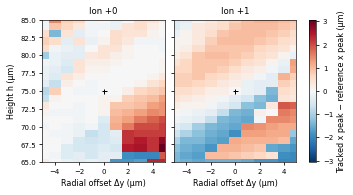

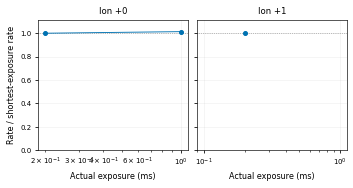

,ion,requested_exposure_ms,actual_exposure_ms,rate_counts_s,rate_relative_to_shortest,passes_thresholds,selected_at_peak
0,0,0.2,0.199618,325622.535211,1.000000,True,False
1,0,1.0,0.999775,330074.240720,1.013671,True,True
2,0,10.0,10.000000,76500.000000,0.234935,False,False
3,0,20.0,20.000000,38250.000000,0.117467,False,False
4,0,45.0,45.000000,16758.932834,0.051467,False,False
5,0,90.0,90.000000,7915.150960,0.024308,False,False
6,1,0.2,0.199618,761455.774648,1.000000,True,True
7,1,1.0,0.999775,655147.356580,0.860388,False,False
8,1,10.0,10.000000,76500.000000,0.100465,False,False
9,1,20.0,20.000000,38250.000000,0.050233,False,False


Data tables, arrays, and analysis settings saved to: /Users/yiyangzhi/GIT/integrated_trapped_ions/Gen_1_Paper/cross_talk_results_ca/publication_97um


In [44]:
require_selected_wavelength(results, WAVELENGTH_NM)
require_scan_wavelength(publication_scan, WAVELENGTH_NM)
# Diagnostics do not modify the requested peak-following calculation.
plot_peak_tracking_diagnostic(publication_scan)
publication_exposure_check = reference_exposure_diagnostic(
    results, PUBLICATION_REFERENCE_HEIGHT_UM, PUBLICATION_DIR, wavelength_nm=WAVELENGTH_NM)
display(publication_exposure_check[["ion", "requested_exposure_ms", "actual_exposure_ms",
    "rate_counts_s", "rate_relative_to_shortest", "passes_thresholds", "selected_at_peak"]])
print(f"Data tables, arrays, and analysis settings saved to: {PUBLICATION_DIR}")


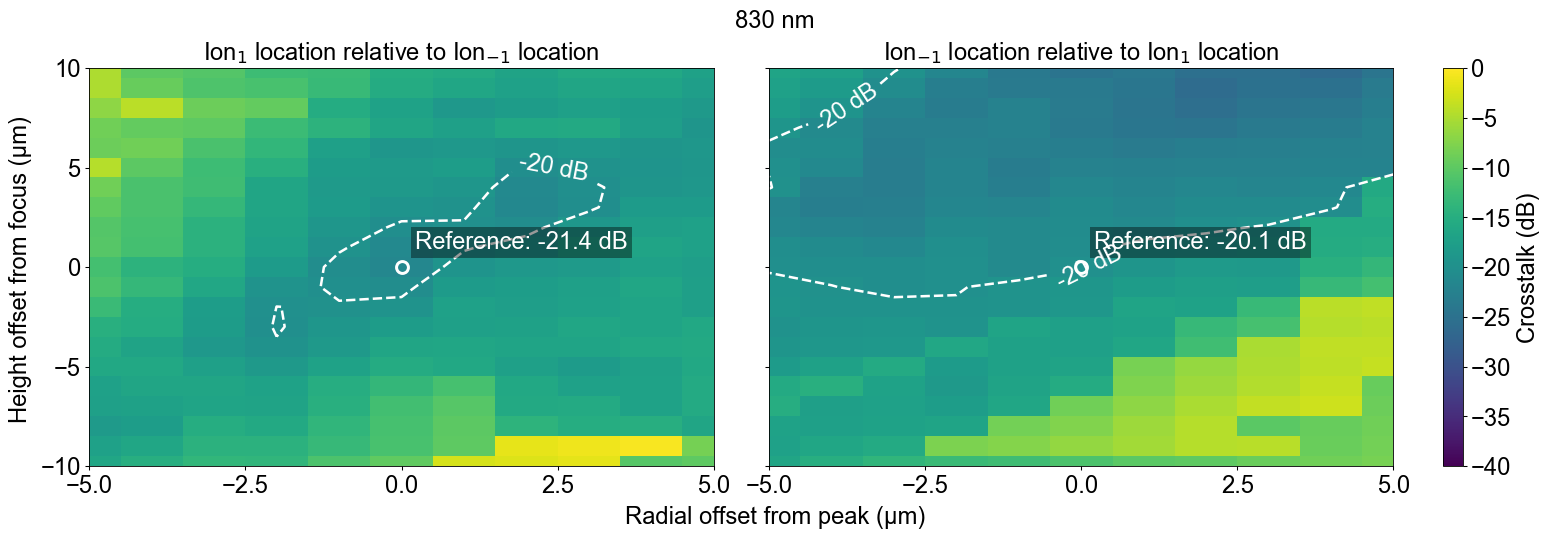

Saved: /Users/yiyangzhi/GIT/integrated_trapped_ions/Gen_1_Paper/cross_talk_results_ca/publication_97um/crosstalk_height_radial_maps_830nm.svg


In [1]:
# Polished two-panel crosstalk maps: Arial 18, display ions -1/+1, SVG only.
# Run the plotting functions and publication-analysis cells above first.
require_scan_wavelength(publication_scan, WAVELENGTH_NM)
polished_height_radial_figure = plot_height_radial_maps(
    publication_scan, color_limits_db=PUBLICATION_DB_LIMITS,
    contour_db=-20.0, font_family="Arial", font_size=18, show=False)
polished_map_svg_path = wavelength_output_path(
    PUBLICATION_DIR, "crosstalk_height_radial_maps.svg", WAVELENGTH_NM)
polished_map_svg_path.parent.mkdir(parents=True, exist_ok=True)
with plt.rc_context({"svg.fonttype": "none", "svg.image_inline": True}):
    polished_height_radial_figure.savefig(polished_map_svg_path, bbox_inches="tight",
                                         facecolor="white", transparent=False)
display(polished_height_radial_figure)
plt.close(polished_height_radial_figure)
print(f"Saved: {polished_map_svg_path}")
